# 架构

SigLIP 保留了 CLIP 的双塔范式，但在三个地方做了关键改造——损失函数由 softmax 换成 sigmoid、视觉池化由 CLS token 换成 MAP 头、激活函数换成 gelu_tanh。 这些改造决定了下面很多看似"细节"的代码写法。

```
pixel_values (B,3,224,224) ──► Vision Tower ──► image_embeds (B,D) ─┐
                                                                    ├─► 归一化 + 相似度 ─► logits (B,B)
input_ids (B,T)            ──► Text   Tower ──► text_embeds  (B,D) ─┘
```

Vision路径：

```
patch_embedding:  (B,3,224,224) → (B,D,14,14) → flatten → (B,196,D)
+ pos embed:      (B,196,D)              位置编码是 (1,196,D) 广播
encoder × L:      (B,196,D) → ... → (B,196,D)   每层恒等
post_layernorm:   (B,196,D)              对最后一维 D 做 LN
MAP head:         (B,196,D) + probe(B,1,D) → attn → (B,1,D) → [:,0] → (B,D)
```

Text路径：

```
token+pos embed:  (B,64) → (B,64,D)
encoder × L:      (B,64,D) → ... → (B,64,D)
final_layernorm:  (B,64,D)
head (Linear):    (B,64,D)  ← 每个 token 独立投影
last-token:       (B,64,D) → [:, -1, :] → (B,D)   左填充，这一位是 EOS
```


输出:


```
image_embeds (B,D), text_embeds (B,D)
→ 归一化 → (B,D)@(D,B) → (B,B)
→ ×exp(scale) + bias → logits (B,B)
→ z = 2I-1，损失为 -log σ(z·logit)，再除以 batch size（不要把 ±1 丢进 BCEWithLogits）
```




In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from dataclasses import dataclass


@dataclass
class SiglipConfig:
    # Vision
    image_size: int = 224
    patch_size: int = 16
    vision_hidden: int = 768 # ← 这就是 D（视觉塔），模型固定超参
    vision_layers: int = 12
    vision_heads: int = 12
    vision_mlp_ratio: float = 4.0
    # Text
    vocab_size: int = 32000
    text_hidden: int = 768 # ← 这也是 D（文本塔，必须相等）
    text_layers: int = 12
    text_heads: int = 12
    text_mlp_ratio: float = 4.0
    max_text_len: int = 64
    # Common
    layer_norm_eps: float = 1e-6


# 标准 FFN：Linear(D→4D) → GELU → Linear(4D→D)，mlp_ratio=4。
# 维度：(B,N,D) → (B,N,4D) → (B,N,D)
class SiglipMLP(nn.Module):
    def __init__(self, dim, ratio=4.0):
        super().__init__()
        hidden = int(dim * ratio)
        self.fc1 = nn.Linear(dim, hidden)
        self.fc2 = nn.Linear(hidden, dim)

    def forward(self, x):
        # SigLIP 使用 gelu_pytorch_tanh，而非 CLIP 的 quick_gelu
        return self.fc2(F.gelu(self.fc1(x), approximate="tanh"))


class SiglipEncoderLayer(nn.Module):
    """Pre-LN Transformer block, 双向注意力（无因果 mask）。"""
    def __init__(self, dim, heads, mlp_ratio=4.0, eps=1e-6):
        super().__init__()
        self.ln1 = nn.LayerNorm(dim, eps=eps) # eps 是 LayerNorm 分母 sqrt(σ² + ε) 里的稳定常数，防止方差为 0 或极小时出现除零
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True) # h 是 (B, 196, 768)，正是 batch_first=True 的 (N, L, E) 格式
        self.ln2 = nn.LayerNorm(dim, eps=eps)
        self.mlp = SiglipMLP(dim, mlp_ratio)

    def forward(self, x, key_padding_mask=None):
        # x: (B, N, D)
        # key_padding_mask: (B, N)，True 表示 PAD，不参与注意力
        h = self.ln1(x)
        h, _ = self.attn(h, h, h, key_padding_mask=key_padding_mask, need_weights=False)
        x = x + h # 注意力残差
        x = x + self.mlp(self.ln2(x)) # MLP 残差
        return x


# ==================== Vision Tower ====================

class SiglipVisionEmbeddings(nn.Module):
    def __init__(self, cfg: SiglipConfig):
        super().__init__()
        # SigLIP 的 patch conv 带 bias
        # 任何仿射层都是 y = Wx + b，bias=True 就是创建并学习这个 b，对于卷积而言就是：每个输出通道加一个常数
        self.patch_embedding = nn.Conv2d(
            3, cfg.vision_hidden,
            kernel_size=cfg.patch_size,
            stride=cfg.patch_size,
            bias=True,
        )
        num_patches = (cfg.image_size // cfg.patch_size) ** 2
        self.position_embedding = nn.Parameter(torch.randn(1, num_patches, cfg.vision_hidden))

    def forward(self, pixel_values):
        # pixel_values: (B, 3, H, W)
        x = self.patch_embedding(pixel_values)          # (B, D, H/P, W/P)
        x = x.flatten(2).transpose(1, 2)                # (B, N, D) N=H*W/(P*P)
        x = x + self.position_embedding                 # (B, N, D)
        return x


class SiglipMultiheadAttentionPoolingHead(nn.Module):
    """MAP 头：可学习的 probe 对 patch tokens 做交叉注意力，然后 LN + MLP + 残差。"""
    def __init__(self, cfg: SiglipConfig):
        super().__init__()
        self.probe = nn.Parameter(torch.randn(1, 1, cfg.vision_hidden)) # 可学习的"探针"向量，是 query(B,1,D)
        self.attention = nn.MultiheadAttention(
            cfg.vision_hidden, cfg.vision_heads, batch_first=True
        )
        self.layernorm = nn.LayerNorm(cfg.vision_hidden, eps=cfg.layer_norm_eps)
        self.mlp = SiglipMLP(cfg.vision_hidden, cfg.vision_mlp_ratio)

    def forward(self, x):
        # x: (B, N, D)
        B = x.shape[0]
        probe = self.probe.expand(B, -1, -1)            # (B, 1, D)
        h, _ = self.attention(probe, x, x, need_weights=False)  # (B, 1, D)
        residual = h
        h = self.layernorm(h)
        h = residual + self.mlp(h)                      # (B, 1, D)
        return h[:, 0]                                  # (B, D)


class SiglipVisionTransformer(nn.Module):
    def __init__(self, cfg: SiglipConfig):
        super().__init__()
        self.embeddings = SiglipVisionEmbeddings(cfg)
        self.encoder = nn.ModuleList([
            SiglipEncoderLayer(cfg.vision_hidden, cfg.vision_heads,
                               cfg.vision_mlp_ratio, cfg.layer_norm_eps)
            for _ in range(cfg.vision_layers)
        ])
        self.post_layernorm = nn.LayerNorm(cfg.vision_hidden, eps=cfg.layer_norm_eps)
        self.head = SiglipMultiheadAttentionPoolingHead(cfg)

    def forward(self, pixel_values):
        x = self.embeddings(pixel_values)               # (B, N, D)
        for layer in self.encoder:
            x = layer(x)
        x = self.post_layernorm(x)                      # (B, N, D)
        pooled = self.head(x)                           # (B, D)
        return pooled


# ==================== Text Tower ====================

class SiglipTextEmbeddings(nn.Module):
    def __init__(self, cfg: SiglipConfig):
        super().__init__()
        self.token_embedding = nn.Embedding(cfg.vocab_size, cfg.text_hidden, padding_idx=0)
        self.position_embedding = nn.Parameter(
            torch.randn(1, cfg.max_text_len, cfg.text_hidden)
        )

    def forward(self, input_ids):
        # input_ids: (B, T)，T ≤ 64
        x = self.token_embedding(input_ids)             # (B, T, D)
        x = x + self.position_embedding[:, :x.size(1), :] # 在文本塔里，x 此时形状是 (B, T, D)，所以 x.size(1) == T，即实际输入的 token 数量。
        return x


class SiglipTextTransformer(nn.Module):
    def __init__(self, cfg: SiglipConfig):
        super().__init__()
        self.embeddings = SiglipTextEmbeddings(cfg)
        self.encoder = nn.ModuleList([
            SiglipEncoderLayer(cfg.text_hidden, cfg.text_heads,
                               cfg.text_mlp_ratio, cfg.layer_norm_eps)
            for _ in range(cfg.text_layers)
        ])
        self.final_layer_norm = nn.LayerNorm(cfg.text_hidden, eps=cfg.layer_norm_eps)
        # SigLIP 的文本 head 带 bias，作用于每个 token
        self.head = nn.Linear(cfg.text_hidden, cfg.text_hidden, bias=True)

    def forward(self, input_ids, padding_mask=None):
        x = self.embeddings(input_ids)                  # (B, T, D)
        for layer in self.encoder:
            x = layer(x, key_padding_mask=padding_mask)
        x = self.final_layer_norm(x)                    # (B, T, D)
        x = self.head(x)                                # (B, T, D)
        # 左填充后，下标 -1 是 EOS。右填充时这一位是 PAD
        return x[:, -1, :]                              # (B, D)


def _init_siglip(model):
    """位置编码用 1/sqrt(width)，词向量用 std=0.02。默认 N(0, 1) 会把初始特征打满。"""
    for module in model.modules():
        if isinstance(module, nn.MultiheadAttention):
            nn.init.xavier_uniform_(module.in_proj_weight)
            nn.init.xavier_uniform_(module.out_proj.weight)
            if module.in_proj_bias is not None:
                nn.init.zeros_(module.in_proj_bias)
            if module.out_proj.bias is not None:
                nn.init.zeros_(module.out_proj.bias)
        elif isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Conv2d):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, std=0.02)
            if module.padding_idx is not None:
                nn.init.zeros_(module.weight[module.padding_idx])
        elif isinstance(module, nn.LayerNorm):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)
    width = model.vision_model.embeddings.position_embedding.shape[-1]
    nn.init.normal_(model.vision_model.embeddings.position_embedding, std=width ** -0.5)
    nn.init.normal_(model.text_model.embeddings.position_embedding, std=width ** -0.5)
    nn.init.normal_(model.vision_model.head.probe, std=width ** -0.5)
    with torch.no_grad():
        model.logit_scale.fill_(math.log(10.0))
        model.logit_bias.fill_(-10.0)


# ==================== Full SigLIP ====================

class SiglipModel(nn.Module):
    def __init__(self, cfg: SiglipConfig):
        super().__init__()
        self.vision_model = SiglipVisionTransformer(cfg)
        self.text_model = SiglipTextTransformer(cfg)
        # 论文初始化：t = log(10)，b = -10。前向用 exp(t)，温度始终为正
        self.logit_scale = nn.Parameter(torch.tensor(math.log(10.0)))
        self.logit_bias = nn.Parameter(torch.tensor(-10.0))
        _init_siglip(self)

    def forward(self, pixel_values, input_ids, padding_mask=None):
        image_embeds = self.vision_model(pixel_values)   # (B, D)
        text_embeds = self.text_model(input_ids, padding_mask)  # (B, D)

        # 归一化后计算余弦相似度，再施加 scale 和 bias
        image_embeds = image_embeds / image_embeds.norm(dim=-1, keepdim=True)
        text_embeds = text_embeds / text_embeds.norm(dim=-1, keepdim=True)

        logits = self.logit_scale.exp() * image_embeds @ text_embeds.t() + self.logit_bias # 点积+常数
        return logits   # (B, B)


# ==================== 维度打印示例 ====================

if __name__ == "__main__":
    cfg = SiglipConfig(
        image_size=224, patch_size=16,
        vision_hidden=192, vision_layers=2, vision_heads=3,
        vocab_size=1000, text_hidden=192, text_layers=2, text_heads=3,
        max_text_len=32,
    )
    model = SiglipModel(cfg).eval()

    B = 2
    pixel_values = torch.randn(B, 3, cfg.image_size, cfg.image_size)
    input_ids = torch.randint(0, cfg.vocab_size, (B, cfg.max_text_len))

    print("=" * 60)
    print("Vision Tower 维度追踪")
    print("=" * 60)
    with torch.no_grad():
        v = model.vision_model.embeddings(pixel_values)
        print(f"patch_embedding 输出:        {tuple(v.shape)}")
        for i, layer in enumerate(model.vision_model.encoder):
            v = layer(v)
            print(f"vision encoder layer {i} 输出: {tuple(v.shape)}")
        v = model.vision_model.post_layernorm(v)
        print(f"post_layernorm 输出:         {tuple(v.shape)}")
        v_pooled = model.vision_model.head(v)
        print(f"MAP head 输出 (image_embeds): {tuple(v_pooled.shape)}")

    print("\n" + "=" * 60)
    print("Text Tower 维度追踪")
    print("=" * 60)
    with torch.no_grad():
        t = model.text_model.embeddings(input_ids)
        print(f"token + position embed 输出:  {tuple(t.shape)}")
        for i, layer in enumerate(model.text_model.encoder):
            t = layer(t)
            print(f"text encoder layer {i} 输出: {tuple(t.shape)}")
        t = model.text_model.final_layer_norm(t)
        print(f"final_layer_norm 输出:       {tuple(t.shape)}")
        t_head = model.text_model.head(t)
        print(f"text head 输出:              {tuple(t_head.shape)}")
        t_pooled = t_head[:, -1, :]
        print(f"last-token 池化 (text_embeds): {tuple(t_pooled.shape)}")

    print("\n" + "=" * 60)
    print("SigLIP 前向输出")
    print("=" * 60)
    with torch.no_grad():
        logits = model(pixel_values, input_ids)
    print(f"pairwise logits:             {tuple(logits.shape)}  (B, B)")

Vision Tower 维度追踪
patch_embedding 输出:        (2, 196, 192)
vision encoder layer 0 输出: (2, 196, 192)
vision encoder layer 1 输出: (2, 196, 192)
post_layernorm 输出:         (2, 196, 192)
MAP head 输出 (image_embeds): (2, 192)

Text Tower 维度追踪
token + position embed 输出:  (2, 32, 192)
text encoder layer 0 输出: (2, 32, 192)
text encoder layer 1 输出: (2, 32, 192)
final_layer_norm 输出:       (2, 32, 192)
text head 输出:              (2, 32, 192)
last-token 池化 (text_embeds): (2, 192)

SigLIP 前向输出
pairwise logits:             (2, 2)  (B, B)


`_init_siglip` 它干的是“开训前把随机数改成合适的尺度”。模型一建出来，PyTorch 已经给 Linear、Embedding、torch.randn 填过默认值。这个函数把那些默认值盖掉，包括：

- 注意力、全连接、patch 卷积改成 Xavier，bias 置 0
- 词向量改成标准差 0.02，PAD 那一行置 0
- LayerNorm 设成权重 1、bias 0
- 图像位置表、文本位置表和 MAP 的 probe 设成 N(0, 1/sqrt(D))
- logit_scale 填 log(10)，logit_bias 填 -10

写完就结束。这些张量之后靠反向传播更新，不再经过 _init_siglip。

# MAP 头（Multihead Attention Pooling Head）完整拆解

MAP 头是 SigLIP 视觉塔的**池化器**，作用是把 `(B, 196, D)` 的 patch 序列聚合成 `(B, D)` 的图像嵌入，**替代 CLIP 的 CLS token 池化**。它就是一个"单 query 的交叉注意力块"。

---

## 一、前向的完整维度追踪（以 base 配置 D=768, H=12, N=196 为例）

```python
def forward(self, x):                                   # x: (B, 196, 768)
    probe = self.probe.expand(B, -1, -1)                # (B, 1, 768)
    h, _ = self.attention(probe, x, x, need_weights=False)  # (B, 1, 768)
    residual = h                                        # (B, 1, 768)
    h = self.layernorm(h)                               # (B, 1, 768)
    h = residual + self.mlp(h)                          # (B, 1, 768)
    return h[:, 0]                                      # (B, 768)
```

逐步展开：

| 步骤 | 操作 | 输入形状 | 输出形状 |
|---|---|---|---|
| 0 | 输入 `x`（已过 `post_layernorm`） | — | `(B, 196, 768)` |
| 1 | `probe` 自 `(1,1,768)` expand 到 batch | `(1,1,768)` | `(B, 1, 768)` |
| 2a | **Q** = `probe @ W_q` | `(B,1,768)` | `(B,1,768)` → 拆头 `(B,12,1,64)` |
| 2b | **K** = `x @ W_k` | `(B,196,768)` | `(B,196,768)` → 拆头 `(B,12,196,64)` |
| 2c | **V** = `x @ W_v` | `(B,196,768)` | `(B,196,768)` → 拆头 `(B,12,196,64)` |
| 3 | `scores = Q·Kᵀ / √64` | `(B,12,1,64) × (B,12,64,196)` | `(B,12,1,196)` |
| 4 | `attn = softmax(scores, -1)` | `(B,12,1,196)` | `(B,12,1,196)` |
| 5 | `out = attn @ V` | `(B,12,1,196) × (B,12,196,64)` | `(B,12,1,64)` |
| 6 | 合并头 + `out_proj` | `(B,12,1,64)` → `(B,1,768)` | `(B,1,768)` |
| 7 | `residual = h`（未归一化） | — | `(B,1,768)` |
| 8 | `h = layernorm(h)` | `(B,1,768)` | `(B,1,768)` |
| 9a | `mlp.fc1`: 768→3072 | `(B,1,768)` | `(B,1,3072)` |
| 9b | GELU(tanh) | `(B,1,3072)` | `(B,1,3072)` |
| 9c | `mlp.fc2`: 3072→768 | `(B,1,3072)` | `(B,1,768)` |
| 10 | `residual + mlp(...)` | `(B,1,768)+(B,1,768)` | `(B,1,768)` |
| 11 | `[:, 0]` 去掉长度为 1 的序列维 | `(B,1,768)` | **`(B, 768)`** |

**关键点**：注意力矩阵只有 `(B, 12, 1, 196)` —— 因为 Q 只有 **1 个 token**，所以 MAP 头非常轻。它做的不是 patch 间的自注意力，而是"**一个探针 query 对 196 个 patch 的加权求和**"。softmax 沿 196 维做，输出是 196 个 V 的凸组合。

---

## 二、各组件参数形状（D=768, H=12）

| 组件 | 参数 | 形状 | 数量 |
|---|---|---|---|
| `probe` | `probe` | `(1, 1, 768)` | 768 |
| `attention` | `in_proj_weight` | `(2304, 768)` | 1,769,472 |
| | `in_proj_bias` | `(2304,)` | 2,304 |
| | `out_proj.weight` | `(768, 768)` | 589,824 |
| | `out_proj.bias` | `(768,)` | 768 |
| `layernorm` | `weight` | `(768,)` | 768 |
| | `bias` | `(768,)` | 768 |
| `mlp.fc1` | `weight` | `(3072, 768)` | 2,359,296 |
| | `bias` | `(3072,)` | 3,072 |
| `mlp.fc2` | `weight` | `(768, 3072)` | 2,359,296 |
| | `bias` | `(768,)` | 768 |
| **合计** | | | **≈ 7.09 M** |

拆解说明：

- **`probe`**：`(1,1,768)`，只 768 个数。`expand(B,-1,-1)` **不复制内存**，只是把 stride 设成 0 让 batch 维广播；真正的复制发生在后面 `W_q` 矩阵乘时。HF 官方用 `.repeat`，效果相同但多一份内存；`expand` 更省。
- **`MultiheadAttention(768, 12)`**：
  - `in_proj_weight` 是 Q/K/V 三块拼在一起的 `(3·768, 768)`；
  - `out_proj` 是注意力输出后的投影 `(768, 768)`；
  - 因为 `kdim = vdim = embed_dim`，PyTorch 会走合并投影的 fast path。
  - 12 个头，每头 `64 = 768/12` 维。
- **`LayerNorm(768)`**：`γ` 和 `β` 各 768。
- **`SiglipMLP(768, 4.0)`**：`fc1: 768→3072`，`fc2: 3072→768`，激活 `gelu_tanh`，ratio=4 使 3072 = 4×768。

**占视觉塔的比例**：ViT-B/16 视觉塔约 86M 参数，MAP 头 ~7.09M ≈ **8.2%**。这和一个普通 encoder block 的参数量差不多：注意力是 Q/K/V/out 四份矩阵共 `4D²`，MLP 是 `2 × 4D² = 8D²`，合计 `12D² ≈ 7.08M`。`in_proj_weight` 的形状始终是 `(3D, D)`，query 只有 1 个 token 并不会让 Q 的参数变少。单 query 省的是计算量：注意力矩阵是 `(B, 12, 1, 196)`，而不是 patch 之间的 `(B, 12, 196, 196)`。

---

## 三、它在哪被调用

只在 `SiglipVisionTransformer.forward` 的最后：

```python
def forward(self, pixel_values):
    x = self.embeddings(pixel_values)      # (B,196,768)
    for layer in self.encoder:
        x = layer(x)                       # (B,196,768)
    x = self.post_layernorm(x)             # (B,196,768)  ← 先 LN
    pooled = self.head(x)                  # (B,768)      ← 再 MAP
    return pooled
```

**顺序很重要**：`post_layernorm` 在 MAP 头**之前**。也就是说 MAP 头看到的 K/V 已经是 LayerNorm 后的 patch 特征。文本塔没有这一步，文本塔在 encoder 后 LN 直接 `head` 投影。视觉塔因为多了 MAP 头，所以多一次 `post_layernorm`。

---

## 四、为什么这样设计（和 CLS 池化的对比）

| | CLIP CLS 池化 | SigLIP MAP 头 |
|---|---|---|
| 池化 token | 训练时 prepend 的 `[CLS]` | 独立 `probe` 参数，**不占序列** |
| 聚合方式 | CLS 在每层自注意力里**间接**吸收 patch 信息 | probe 在最后**显式**做一次交叉注意力 |
| 序列长度 | 197（含 CLS） | 196（纯 patch） |
| 池化后处理 | 直接 `LN(CLS)` 取用 | `attn → LN → MLP → residual` 再做一层非线性 |
| 参数量 | CLS 是 `(1,768)` 的 pos embed 位 | ~7.09M（多一个注意力块） |
| 对分辨率变化 | CLS 与 patch 数关系由注意力隐式决定 | probe 与 patch 数关系由 softmax 动态决定 |

**设计意图**：

1. **更显式的聚合**：CLS 靠 12 层自注意力"顺便"聚合信息；MAP 头用专门的可学习 query 在最后主动"查询"所有 patch，参数只花在一处、目标明确。
2. **池化本身带非线性**：CLS 池化后通常只接一个 Linear；MAP 头在聚合后接 `LN + MLP + 残差`，相当于给池化结果再做一次变换，表达力更强。
3. **序列更干净**：196 个 token 全是真实 patch，没有 CLS 这个"占位符"，位置编码也只对应真实 patch 位置。
4. **和分辨率的关系**：probe 对多少个 patch 做 softmax 是动态的，序列里没有一个要占位置编码的 CLS。MAP 来自 ViT / big_vision 的池化方式。SigLIP 论文的消融主要比较 sigmoid 与 softmax、bias 初值和 batch size，不要把“MAP 优于 CLS”写成那篇论文里的实验结果。

---

## 五、两个容易踩的细节

### 1. `residual` 是**未归一化**的注意力输出

```python
h, _ = self.attention(...)   # h 是注意力原始输出
residual = h                  # 残差保存"原始" h
h = self.layernorm(h)         # LN 只作用于进 MLP 的那条路
h = residual + self.mlp(h)    # 残差加的是"原始 h + MLP(LN(h))"
```

这是 **Pre-LN 残差**风格：`out = h + MLP(LN(h))`，和 encoder block 里 `x + MLP(LN(x))` 一致。**不是** `LN(h + MLP(h))`（Post-LN）。这一点在加载官方权重、做逐层数值对齐时很重要。

### 2. `probe` 用 `expand` 而非 `repeat`

```python
probe = self.probe.expand(B, -1, -1)   # (1,1,D) → (B,1,D)，stride=0，不复制
```

`expand` 在 batch 维上把 stride 设为 0，所有 batch 共享同一份 `probe` 内存。只要后续不对 `probe` 做 in-place 修改就没问题——而 `attention` 内部是矩阵乘，不修改输入，所以安全。HF 官方用 `.repeat(B,1,1)`（真实复制），两者数值完全等价，`expand` 省一份 `B×768` 的内存。

---

## 六、一句话总结

**MAP 头 = 一个 `(B,1,D)` 的可学习 probe 作为 Q，对 `(B,N,D)` 的 patch 特征做 K/V 交叉注意力，得到 `(B,1,D)` 的聚合向量，再经 `Pre-LN 残差 + MLP` 变换，最后 `[:,0]` 取成 `(B,D)`。输入 `(B,196,768)`，输出 `(B,768)`；参数量约 7.09M（base 配置），由 `probe(768) + MHA(2.36M) + LN(1.5K) + MLP(4.72M)` 构成，占视觉塔约 8%。**

# 为什么取最后一个 token 就能代表整句语义

这是文本塔里最容易让人觉得"魔法"的一步。先说结论：**不是"最后一个 token 天然有语义"，而是"EOS 这个位置被训练目标专门优化成了整句摘要位，而预处理约定保证 EOS 在最后"**。拆开看是三层原因叠加。

---

## 一、先纠正一个前提：取的不是"最后一个词"，是 EOS 的位置

```python
return x[:, -1, :]
```

`[:, -1, :]` 取的是**序列最后一个位置**。它能成立，靠的是 SigLIP 的预处理约定：

- 文本 **截断并填充到固定长度**（官方是 64）；
- **EOS 接在有效内容后面，PAD 补在左边**。官方 `SiglipTokenizer` 的 `padding_side="left"`，所以 EOS 固定占最后一位。

右填充时，下标 `-1` 是 PAD。EOS 只是“最后一个非 PAD 位”，和 `-1` 不是同一个位置：

```
右填充: [a, dog, EOS, PAD, PAD, ..., PAD]   下标 -1 = PAD
左填充: [PAD, PAD, ..., PAD, a, dog, EOS]   下标 -1 = EOS
```

`[:, -1]` 取到 EOS，前提是左填充。句子刚好写满 64、后面没有 PAD 时，两种填充才会碰巧重合。

但"取到 EOS"本身还不解释为什么 EOS 能代表整句——这是下面两层要回答的。

---

## 二、双向注意力：EOS 位置在结构上"看得到"整句

文本塔的 encoder 是**双向、无 causal mask** 的：

```python
h, _ = self.attn(h, h, h, need_weights=False)   # 没有 attn_mask
```

这意味着**每个 token 都能看到所有 token**，包括 EOS。经过 12 层后，EOS 位置的向量已经通过注意力**聚合了整句所有 token 的信息**——它在第 1 层就 attend 到全句，第 2 层 attend 到"已经聚合过的全句"，层层叠加。

所以从**信息可达性**上说，EOS 位置确实持有整句信息。但注意：**双向注意力下，理论上任何位置（包括第一个词）也都看得到整句**。信息可达性不是 EOS 独有的。真正的区别在下一层。

> 对照 CLIP：CLIP 的文本塔是 **causal mask**（GPT 式），最后一个 token 在结构上**只能**看到前面所有 token、看不到后面，所以它天然是"前缀累积表示"。SigLIP 改成双向后，这个结构保证消失了，必须靠训练目标来指定聚合位——这正是第三层。

---

## 三、训练目标把 EOS 位置"选"成了语义锚点

这是最关键的一层。对比损失只作用于**两塔最终输出的嵌入**：

```python
text_embeds = self.text_model(input_ids)   # 只有 (B,D)，来自左填充后的 [:, -1]
logits = scale * image_embeds @ text_embeds.t() + bias
loss = -logsigmoid(z * logits).sum() / B   # z 对角线为 +1，其余为 -1
```

梯度只从 `text_embeds` 这一条路径回传，而 `text_embeds` 正是 `x[:, -1, :]`。于是：

1. **只有 EOS 位置的输出被要求"和图像语义对齐"**。第一个词、中间的词、pad 位的输出**没有任何监督信号**要求它们成为整句摘要。
2. 反向传播会**专门把 EOS 位置的表示往"整句语义 + 图像对齐"的方向推**。经过大量训练，EOS 位置被"雕刻"成一个聚合器：它学会从所有 token 里抽取与图像匹配的信息，压缩成一个向量。
3. 其他位置虽然信息上也能看到全句，但**没有被训练目标选中**，所以它们的表示不会被优化成摘要——它们只是"顺便"参与了 EOS 的聚合。

用一个类比：BERT 的 `[CLS]` token 本身没有任何词汇语义，但预训练目标（NSP/MLM 的句级部分）把它训练成整句表示。**SigLIP 的 EOS 就是这个角色，只不过它在句尾、且 SigLIP 用的是双向编码器 + 对比损失。** "语义锚点"不是 token 自带的属性，是**训练目标赋予的角色**。

---

## 四、为什么选"最后"而不是"第一个"

在双向注意力下，选哪个位置做聚合位在**理论上都可行**（只要训练时一致）。SigLIP 选最后一个，主要是三个工程/历史原因：

1. **和 CLIP 保持一致**：CLIP 因为 causal mask 必须用最后位置，SigLIP 沿用这个接口约定，方便生态迁移。
2. **左填充把 EOS 钉在最后一位**：常见做法是右填充，但那样下标 `-1` 是 PAD。SigLIP 用左填充，EOS 永远在最后，就可以直接切 `[:, -1]`。CLIP 用 `input_ids.argmax(-1)` 找 EOT，是因为 EOT 的 id 是词表里最大的，不是因为 `argmax(input_ids == eos_id)`。
3. **直觉上"读完再总结"**：位置编码让 EOS 在序列末尾，符合"句子结束才形成摘要"的叙事，但这不是数学必需。

> 换句话说：**"最后"是约定，"EOS 被训练成锚点"才是本质。** 如果 SigLIP 当初把 EOS 放开头、训练目标取 `[:, 0]`，也能训出语义锚点——只是接口会和 CLIP 不兼容。

---

## 五、这套设计的脆弱点（也是复现时最容易踩的坑）

因为 `[:, -1]` 是**硬编码位置**，它完全依赖预处理约定。以下任一情况都会让语义锚点失效：

| 问题 | 后果 |
|---|---|
| EOS 没放在有效内容末尾 | `[:, -1]` 取到 pad 或随机词，文本嵌入无意义 |
| 右填充，而不是左填充 | 下标 -1 是 PAD，池化读到 PAD 位 |
| 没有填充到固定长度 | 各样本的 EOS 不在同一下标，硬编码的 `[:, -1]` 会取到不同角色的 token |
| 截断时把 EOS 截掉了 | 最后一位是实词而非 EOS，锚点偏移 |

所以官方 tokenizer 的 `padding="max_length"`、`truncation=True`、`max_length=64`、`padding_side="left"` 是架构的一部分。自己写预处理时，要在截断后仍保留 EOS，把 PAD 放在左边，并在注意力里 mask 掉这些 PAD。

---

## 六、和 CLIP 的完整对比

| | CLIP | SigLIP |
|---|---|---|
| 文本注意力 | **causal mask**（单向） | **双向**（无 mask） |
| 最后 token 为何能聚合 | **结构保证**：因果注意力下最后一位只能看前面，天然是前缀累积 | **训练目标保证**：双向下谁都能看全句，只有被损失选中的位置被优化成聚合器 |
| 取法 | `input_ids.argmax(-1)`，因为 EOT id 是词表最大值 | 直接 `[:, -1, :]`，靠左填充把 EOS 放在末位 |
| 池化后处理 | `pooler`（Linear + tanh） | `Linear(D,D, bias=True)`，无 tanh |
| 本质 | 结构 + 训练共同决定 | **完全靠训练目标 + 约定** |

这个对比说明：**SigLIP 把"聚合位"从"结构保证"降级成了"训练约定"**，换来的是双向注意力带来的更强上下文建模（每个 token 都能看全句，而非只看前缀）。代价是必须严格守 pad 约定——这是复现时不能省略的细节。

---

## 七、一句话总结

**`x[:, -1, :]` 取的是 EOS 位置的表示。它能代表整句，是因为（1）左填充把 EOS 固定在下标 -1、（2）双向注意力让这个位置看得到整句、（3）对比损失只监督这个位置，把它训练成“整句↔图像”对齐的聚合器。三者缺一不可。**

# 归一化与 logits 计算逐行拆解

这段代码做三件事：**L2 归一化 → 点积得到余弦相似度 → 温度缩放 + 偏置**。下面按维度、数值、设计动机三层展开。

```python
image_embeds = image_embeds / image_embeds.norm(dim=-1, keepdim=True)
text_embeds  = text_embeds  / text_embeds.norm(dim=-1, keepdim=True)
logits = self.logit_scale.exp() * image_embeds @ text_embeds.t() + self.logit_bias
```

---

## 一、`.norm(dim=-1, keepdim=True)` 是什么

`Tensor.norm(p=2, dim, keepdim)` 默认求 **L2 范数**（欧几里得长度）：

$$
\|x\|_2 = \sqrt{\sum_{i} x_i^2}
$$

对嵌入 `(B, D)` 的每个样本（沿最后一维 D 求范数）：

| 参数 | 值 | 作用 |
|---|---|---|
| `dim=-1` | 最后一维 | 对 D 维求范数，**每个样本得到一个标量** |
| `keepdim=True` | 保留该维 | 结果形状 `(B, 1)` 而非 `(B,)`，便于广播 |

维度追踪：

```
image_embeds               (B, D)
image_embeds.norm(dim=-1)          (B,)      ← keepdim=False 时
image_embeds.norm(-1, keepdim=True) (B, 1)   ← keepdim=True
```

**为什么必须 `keepdim=True`**：下一步做除法 `(B,D) / (B,1)`，`(B,1)` 会沿最后一维**广播**到 `(B,D)`——每个样本的 D 个分量都除以**自己**的范数。如果 `keepdim=False` 得到 `(B,)`，`(B,D) / (B,)` 会按最后一维广播，变成"第 j 个分量除以第 j 个样本的范数"——**语义完全错了**，而且形状刚好能对上（D == B 时才不报错），是个隐蔽 bug。

---

## 二、L2 归一化：把向量压到单位球面

```python
image_embeds = image_embeds / image_embeds.norm(dim=-1, keepdim=True)
```

即 `x_hat = x / ‖x‖₂`。效果：

- 每个样本变成**长度为 1 的单位向量**：`‖x_hat‖₂ = 1`；
- 只保留**方向**，丢弃**模长**；
- 所有嵌入落在 D 维单位球面上。

数值例子（D=3）：

```
x = [3, 4, 0]        ‖x‖ = 5
x_hat = [0.6, 0.8, 0]   ‖x_hat‖ = 1
```

**为什么要归一化**：

1. **点积 = 余弦相似度**。对单位向量，`a·b = ‖a‖‖b‖cosθ = cosθ ∈ [-1,1]`。不归一化的话点积会被模长主导（长向量点积大），相似度失去可比性。
2. **训练稳定**：嵌入模长在训练中会漂移，归一化后相似度有界，logit 不会爆炸。
3. **和 sigmoid 损失配套**：sigmoid 是逐 pair 独立二分类，需要 logit 落在合理区间；余弦相似度天然有界，加 bias 后容易校准。

> `+ 1e-8` 之类的 eps 在这里**没有**——因为嵌入是 LayerNorm/MLP 输出，范数不会为 0。有些实现会加，SigLIP 官方没有。

---

## 三、点积：`image_embeds @ text_embeds.t()`

```python
image_embeds @ text_embeds.t()
```

维度：

```
image_embeds     (B, D)      ← 已归一化
text_embeds.t()  (D, B)      ← 转置
@                (B, D) @ (D, B) → (B, B)
```

结果 `S ∈ R^{B×B}`，`S[i][j] = image_i · text_j = cos(image_i, text_j)`。

| | text_0 | text_1 | ... | text_{B-1} |
|---|---|---|---|---|
| **image_0** | cos(i0,t0) | cos(i0,t1) | | |
| **image_1** | cos(i1,t0) | cos(i1,t1) | | |
| ... | | | | |
| **image_{B-1}** | | | | cos(i_{B-1},t_{B-1}) |

**对角线** `S[i][i]` 是配对正样本的相似度，**非对角**是负样本对。这就是对比学习的核心矩阵——每行每列各有一个正样本，其余都是负样本。

注意：`@` 在 PyTorch 里对 2D 张量就是矩阵乘，等价 `torch.matmul` / `torch.mm`。这里用 `@` 只是 Python 运算符重载，可读性更好。

---

## 四、温度：`self.logit_scale.exp()`

```python
self.logit_scale = nn.Parameter(torch.tensor(math.log(10.0)))  # 存的是 log 温度
self.logit_scale.exp()                                         # 前向得到 10
```

`logit_scale` 是一个**标量可学习参数**，直接用它做缩放不能保证正数。所以存的是 **log 温度**，用时 `exp()` 恢复：

$$
\text{scale} = e^{\,\text{logit\_scale}} > 0
$$

- SigLIP 初始化为 `logit_scale = log(10)`，因此一开始 `scale = 10`；
- CLIP 惯例初始化为 `ln(1/0.07) ≈ 2.659`，对应 `scale ≈ 14.29`（温度 0.07）。

**温度的作用**：`scale · cos` 控制相似度分布的"尖锐程度"。

- `scale` 大 → logit 差距被放大 → sigmoid/softmax 输出更接近 0/1 → 模型更"自信"，梯度更集中；
- `scale` 小 → logit 平缓 → 输出接近 0.5 → 梯度分散。

训练中 `logit_scale` 会被优化，让模型自己学"该多自信"。**用 `exp` 参数化是标准技巧**：保证正数、梯度更稳定（`d(exp(s))/ds = exp(s)`，不会因 s 过小而梯度消失）。CLIP/SigLIP 都这么做。

维度：标量 × `(B,B)` → 广播成 `(B,B)`，每个元素乘同一个数。

---

## 五、偏置：`+ self.logit_bias`（SigLIP 独有）

```python
self.logit_bias = nn.Parameter(torch.tensor(-10.0))   # 论文初值
```

又是一个**标量**，加到 `(B,B)` 的每个 logit 上，广播。

**这是 SigLIP 相对 CLIP 的关键差异**，原因在损失函数：

- **CLIP 用 softmax**：`softmax(z + c) = softmax(z)`，全局加常数被归一化**抵消**，所以 CLIP 的 bias 无意义、不需要。
- **SigLIP 用 sigmoid**：逐 pair 独立做 `σ(z)`，**没有跨样本归一化**。正样本对和负样本对的 logit 需要落在不同区间（正样本 logit 应该高、负样本应该低），但余弦相似度初始均值接近 0，`σ(0)=0.5` 对正负样本都一样，梯度信号弱。加一个**可学习 bias** 让模型能校准"正样本的基准 logit"，论文证明这对训练稳定性和最终性能至关重要。

一句话：**softmax 自带"零和"约束，sigmoid 没有，所以必须用 bias 补上这个自由度。** 论文把 bias 初始化为 **-10**，把 `logit_scale` 初始化为 **log(10)**。随机向量的余弦接近 0，于是初始 logit ≈ -10：负样本的损失接近 0，正样本大约贡献 10，开训时的 loss 就在 10 附近。从 0 开始学 bias 也行，但一个 batch 里负样本远多于正样本，前期梯度会先把全部分数往下压。

---

## 六、完整前向的维度与数值示例

设 `B=2, D=4`：

```python
image_embeds = [[3,4,0,0], [1,0,0,0]]      # 未归一化
text_embeds  = [[0,0,3,4], [0,1,0,0]]

# 1) 范数 (B,1)
image_norm = [[5],[1]]
text_norm  = [[5],[1]]

# 2) 归一化 (B,4)
image_embeds = [[0.6,0.8,0,0], [1,0,0,0]]
text_embeds  = [[0,0,0.6,0.8], [0,1,0,0]]

# 3) 点积 (B,B)
S = image_embeds @ text_embeds.T
  = [[0.6*0+0.8*0+0*0.6+0*0.8,   0.6*0+0.8*1+0+0],
     [1*0+0+0+0,                 1*0+0*1+0+0]]
  = [[0.0, 0.8],
     [0.0, 0.0]]

# 4) 缩放 + 偏置（手算用 scale=e、bias=0；论文初值是 scale=10、bias=-10）
logits = e * S + 0
       = [[0.0, 2.174],
          [0.0, 0.0]]

# 5) sigmoid（下一步，不在本段代码）
#   正样本 (0,0) 和 (1,1)：σ(0.0), σ(0.0)
#   负样本 (0,1) 和 (1,0)：σ(2.174), σ(0.0)
```

可以看到：归一化把模长差异抹平了（原本 `[3,4,0,0]` 和 `[1,0,0,0]` 模长差 5 倍，归一化后都是单位向量）；点积直接就是余弦；`scale` 把 `[0, 0.8]` 放大成 `[0, 2.17]`，让 sigmoid 后的区分度更明显。

---

## 七、输出是什么、下一步是什么

```python
return logits   # (B, B)
```

返回的是**原始 logit 矩阵**，**没有经过 sigmoid/softmax**。这是刻意的：

- 损失吃的是原始 logit。`binary_cross_entropy_with_logits` 的目标是 **0 和 1**，不能传入 ±1。对角线目标 1、其余目标 0，并且 `reduction="sum"` 后再除以 batch size，才和论文的 `/B` 一致；默认 `mean` 除的是 `B²`。
- 训练代码用的是等价形式：`z = 2I-1`，损失 `-logsigmoid(z * logits).sum() / B`。`z = +1` 对应 BCE 目标 1，`z = -1` 对应 BCE 目标 0。
- CLIP 的 `cross_entropy` 同样不需要在这里先做 softmax。

所以这段代码的职责到"产生 pairwise logit"为止，**激活函数由损失函数负责**。这也是为什么函数名叫 `logits` 而不是 `probs` 或 `similarity`——它明确表示"未归一化的分数"。

SigLIP 的损失有两种等价写法。训练格子用的是第一种，它直接接受 ±1 标签：

```python
# 论文形式。z 对角线 +1，其余 -1。除以 batch size，不是除以配对数
z = 2 * torch.eye(B, device=logits.device) - 1
loss = -F.logsigmoid(z * logits).sum() / B

# 等价的 BCE。目标必须是 0/1；sum 再除以 B，才和上面同一个数
target = torch.eye(B, device=logits.device)
loss = F.binary_cross_entropy_with_logits(logits, target, reduction="sum") / B
```

每个 pair 独立做二分类，没有 softmax 的跨样本耦合。把 ±1 直接丢进 `binary_cross_entropy_with_logits` 是错的：那个函数把目标当成 0/1 的软标签，负样本那一项对不上 `-log σ(-logit)`。

---

## 八、和 CLIP 的对照表

| 步骤 | CLIP | SigLIP | 代码位置 |
|---|---|---|---|
| 归一化 | L2 | L2（相同） | `embeds / embeds.norm(...)` |
| 相似度 | 点积 = 余弦 | 点积 = 余弦（相同） | `@ .t()` |
| 温度参数化 | `logit_scale.exp()` | `logit_scale.exp()`（相同） | `logit_scale` |
| 偏置 | **无** | **`logit_bias`**（独有） | `logit_bias` |
| 激活 | softmax（损失内） | **sigmoid**（损失内） | 不在本段 |
| 跨样本耦合 | 有（softmax 分母） | **无**（逐 pair 独立） | — |

---

## 九、一句话总结

**这两行归一化把 `(B,D)` 的嵌入压成单位向量（`keepdim=True` 保证按样本广播），使点积退化为余弦相似度 `∈[-1,1]`；`image_embeds @ text_embeds.t()` 得到 `(B,B)` 的 pairwise 相似度矩阵；`logit_scale.exp()` 是可学习的正温度（存 log 保证正数），`logit_bias` 是 SigLIP 独有的可学习偏置——因为 sigmoid 损失没有 softmax 的归一化来抵消全局偏置，必须显式提供这个校准自由度。输出的 `(B,B)` 是未激活的 logit。sigmoid 在损失里完成：要么 `-log σ(z·logit)`，要么目标为 0/1 的 `binary_cross_entropy_with_logits`。**

---

# 实战1

数据用 Flickr8k-2k：从 Flickr8k 里抽 2000 张图，每张仍是原来的 5 句 caption（说明文字）。划分沿用官方 train/dev/test 名单的前面一部分：1600 / 200 / 200。模型、左填充、sigmoid 损失和上面一致，宽度和层数缩小，只为把这套算法在真实图文上跑通。


In [ ]:
from pathlib import Path
root = Path("flickr8k-2k")
if not root.exists():
    root = Path("/home/ygz/cursor_workspace/Paper/SigLIP/flickr8k-2k")
need = ["Flickr8k.token.txt", "trainImages.txt", "devImages.txt", "testImages.txt", "Flicker8k_Dataset"]
missing = [name for name in need if not (root / name).exists()]
if missing:
    raise FileNotFoundError(f"{root} 缺少 {missing}")
n_img = len(list((root / "Flicker8k_Dataset").glob("*.jpg")))
print(f"Flickr8k-2k: {root}  images={n_img}")


In [ ]:
import os, math, random, re
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm

# ============================================================
# 0. 配置与随机种子
# ============================================================
def set_seed(s=42):
    random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# ============================================================
# 1. 自定义轻量分词器（替代 HuggingFace tokenizer）
# ============================================================
class SimpleTokenizer:
    """按空格/标点切分，构建词表，支持 pad/truncate 到固定长度。"""
    def __init__(self, max_len=64, vocab_size=10000):
        self.max_len = max_len
        self.vocab_size = vocab_size
        self.word2id = {"<pad>": 0, "<unk>": 1, "<eos>": 2}
        self.id2word = {v: k for k, v in self.word2id.items()}

    def build_vocab(self, captions):
        counter = Counter()
        for cap in captions:
            tokens = self._tokenize(cap)
            counter.update(tokens)
        # 取最高频的 vocab_size - 3 个词
        for word, _ in counter.most_common(self.vocab_size - 3):
            if word not in self.word2id:
                idx = len(self.word2id)
                self.word2id[word] = idx
                self.id2word[idx] = word
        print(f"Vocab size: {len(self.word2id)}")

    def _tokenize(self, text):
        text = text.lower().strip()
        # 简单正则：按非字母数字切分
        tokens = re.findall(r"[a-z0-9']+", text)
        return tokens

    def encode(self, text):
        """左填充，使 EOS 落在最后一位。padding_mask 里 True 表示 PAD。"""
        tokens = self._tokenize(text)[: self.max_len - 1]
        body = [self.word2id.get(t, 1) for t in tokens] + [2]  # 2 = <eos>
        pad = self.max_len - len(body)
        ids = [0] * pad + body
        padding_mask = [True] * pad + [False] * len(body)
        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(padding_mask, dtype=torch.bool),
        )

# ============================================================
# 2. Flickr8k-2k：2000 张图，每张 5 句 caption
#    1600 train / 200 dev / 200 test，取自官方划分名单的前若干张
# ============================================================
def read_tokens(token_file):
    img2caps = {}
    with open(token_file, encoding="utf-8") as f:
        for raw in f:
            line = raw.strip()
            if "\t" not in line:
                continue
            image_id, caption = line.split("\t", 1)
            image_id = image_id.split("#", 1)[0].strip()
            caption = caption.strip()
            if image_id and caption:
                img2caps.setdefault(image_id, []).append(caption)
    return img2caps

def read_ids(split_file):
    with open(split_file, encoding="utf-8") as f:
        return [line.strip() for line in f if line.strip()]

class Flickr8kDataset(Dataset):
    def __init__(self, img_dir, image_ids, img2caps, tokenizer, image_size, train=False):
        self.img_dir = Path(img_dir)
        self.samples = image_ids
        self.img2caps = img2caps
        self.tokenizer = tokenizer
        self.train = train
        # 验证用中心裁切。训练随机裁一点，避免 1600 张图被按像素记住。
        if train:
            geom = [
                transforms.RandomResizedCrop(
                    image_size, scale=(0.8, 1.0),
                    interpolation=transforms.InterpolationMode.BICUBIC,
                ),
            ]
        else:
            geom = [
                transforms.Resize(image_size, interpolation=transforms.InterpolationMode.BICUBIC),
                transforms.CenterCrop(image_size),
            ]
        self.transform = transforms.Compose(geom + [
            transforms.ToTensor(),
            transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
        ])

    def __len__(self):
        return len(self.samples)

    def load_pil(self, idx):
        with Image.open(self.img_dir / self.samples[idx]) as im:
            return im.convert("RGB")

    def __getitem__(self, idx):
        pixel = self.transform(self.load_pil(idx))
        caps = self.img2caps[self.samples[idx]]
        cap = random.choice(caps) if self.train else caps[0]
        ids, padding_mask = self.tokenizer.encode(cap)
        return pixel, ids, padding_mask

# ============================================================
# 3. SigLIP 模型（与之前架构完全一致）
# ============================================================
@dataclass
class SiglipConfig:
    image_size: int = 224
    patch_size: int = 16
    vision_hidden: int = 768
    vision_layers: int = 12
    vision_heads: int = 12
    vision_mlp_ratio: float = 4.0
    vocab_size: int = 10000
    text_hidden: int = 768
    text_layers: int = 12
    text_heads: int = 12
    text_mlp_ratio: float = 4.0
    max_text_len: int = 64
    layer_norm_eps: float = 1e-6

class SiglipMLP(nn.Module):
    def __init__(self, dim, ratio=4.0):
        super().__init__()
        hidden = int(dim * ratio)
        self.fc1 = nn.Linear(dim, hidden)
        self.fc2 = nn.Linear(hidden, dim)
    def forward(self, x):
        return self.fc2(F.gelu(self.fc1(x), approximate="tanh"))

class SiglipEncoderLayer(nn.Module):
    def __init__(self, dim, heads, mlp_ratio=4.0, eps=1e-6):
        super().__init__()
        self.ln1 = nn.LayerNorm(dim, eps=eps)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.ln2 = nn.LayerNorm(dim, eps=eps)
        self.mlp = SiglipMLP(dim, mlp_ratio)
    def forward(self, x, key_padding_mask=None):
        h = self.ln1(x)
        # True 表示 PAD。视觉塔不传 mask
        h, _ = self.attn(h, h, h, key_padding_mask=key_padding_mask, need_weights=False)
        x = x + h
        x = x + self.mlp(self.ln2(x))
        return x

class SiglipVisionEmbeddings(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.patch_embedding = nn.Conv2d(3, cfg.vision_hidden, cfg.patch_size, cfg.patch_size, bias=True)
        n = (cfg.image_size // cfg.patch_size) ** 2
        self.position_embedding = nn.Parameter(torch.randn(1, n, cfg.vision_hidden))
    def forward(self, pixel_values):
        x = self.patch_embedding(pixel_values).flatten(2).transpose(1, 2)
        return x + self.position_embedding

class SiglipMultiheadAttentionPoolingHead(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.probe = nn.Parameter(torch.randn(1, 1, cfg.vision_hidden))
        self.attention = nn.MultiheadAttention(cfg.vision_hidden, cfg.vision_heads, batch_first=True)
        self.layernorm = nn.LayerNorm(cfg.vision_hidden, eps=cfg.layer_norm_eps)
        self.mlp = SiglipMLP(cfg.vision_hidden, cfg.vision_mlp_ratio)
    def forward(self, x):
        B = x.shape[0]
        probe = self.probe.expand(B, -1, -1)
        h, _ = self.attention(probe, x, x, need_weights=False)
        residual = h
        h = self.layernorm(h)
        h = residual + self.mlp(h)
        return h[:, 0]

class SiglipVisionTransformer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.embeddings = SiglipVisionEmbeddings(cfg)
        self.encoder = nn.ModuleList([
            SiglipEncoderLayer(cfg.vision_hidden, cfg.vision_heads, cfg.vision_mlp_ratio, cfg.layer_norm_eps)
            for _ in range(cfg.vision_layers)
        ])
        self.post_layernorm = nn.LayerNorm(cfg.vision_hidden, eps=cfg.layer_norm_eps)
        self.head = SiglipMultiheadAttentionPoolingHead(cfg)
    def forward(self, pixel_values):
        x = self.embeddings(pixel_values)
        for layer in self.encoder:
            x = layer(x)
        return self.head(self.post_layernorm(x))

class SiglipTextEmbeddings(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.token_embedding = nn.Embedding(cfg.vocab_size, cfg.text_hidden, padding_idx=0)
        self.position_embedding = nn.Parameter(torch.randn(1, cfg.max_text_len, cfg.text_hidden))
    def forward(self, input_ids):
        x = self.token_embedding(input_ids)
        return x + self.position_embedding[:, :x.size(1), :]

class SiglipTextTransformer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.embeddings = SiglipTextEmbeddings(cfg)
        self.encoder = nn.ModuleList([
            SiglipEncoderLayer(cfg.text_hidden, cfg.text_heads, cfg.text_mlp_ratio, cfg.layer_norm_eps)
            for _ in range(cfg.text_layers)
        ])
        self.final_layer_norm = nn.LayerNorm(cfg.text_hidden, eps=cfg.layer_norm_eps)
        self.head = nn.Linear(cfg.text_hidden, cfg.text_hidden, bias=True)
    def forward(self, input_ids, padding_mask=None):
        x = self.embeddings(input_ids)
        for layer in self.encoder:
            x = layer(x, key_padding_mask=padding_mask)
        x = self.head(self.final_layer_norm(x))
        # 左填充后，下标 -1 是 EOS
        return x[:, -1, :]


def _init_siglip(model):
    """位置编码 1/sqrt(width)，词向量 std=0.02。默认 N(0,1) 会把初始激活打满。"""
    for module in model.modules():
        if isinstance(module, nn.MultiheadAttention):
            nn.init.xavier_uniform_(module.in_proj_weight)
            nn.init.xavier_uniform_(module.out_proj.weight)
            if module.in_proj_bias is not None:
                nn.init.zeros_(module.in_proj_bias)
            if module.out_proj.bias is not None:
                nn.init.zeros_(module.out_proj.bias)
        elif isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Conv2d):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, std=0.02)
            if module.padding_idx is not None:
                nn.init.zeros_(module.weight[module.padding_idx])
        elif isinstance(module, nn.LayerNorm):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)
    width = model.vision_model.embeddings.position_embedding.shape[-1]
    nn.init.normal_(model.vision_model.embeddings.position_embedding, std=width ** -0.5)
    nn.init.normal_(model.text_model.embeddings.position_embedding, std=width ** -0.5)
    nn.init.normal_(model.vision_model.head.probe, std=width ** -0.5)
    with torch.no_grad():
        model.logit_scale.fill_(math.log(10.0))
        model.logit_bias.fill_(-10.0)


class SiglipModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.vision_model = SiglipVisionTransformer(cfg)
        self.text_model = SiglipTextTransformer(cfg)
        self.logit_scale = nn.Parameter(torch.tensor(math.log(10.0)))
        self.logit_bias = nn.Parameter(torch.tensor(-10.0))
        _init_siglip(self)
    def forward(self, pixel_values, input_ids, padding_mask=None):
        img = F.normalize(self.vision_model(pixel_values), dim=-1)
        txt = F.normalize(self.text_model(input_ids, padding_mask), dim=-1)
        logits = self.logit_scale.exp() * img @ txt.t() + self.logit_bias
        return logits

def siglip_loss(logits):
    """z = 2I-1。不要把 ±1 丢进 BCEWithLogits，那个函数的目标是 0/1。"""
    B = logits.shape[0]
    labels = 2 * torch.eye(B, device=logits.device) - 1
    return -F.logsigmoid(labels * logits).sum() / B

# ============================================================
# 4. 数据加载与分词器构建
# ============================================================
IMAGE_SIZE = 224
MAX_LEN = 64
# loss = 所有 pair 的和 / B，随机猜的下界大约是 log(B)。
# 训练用 128、验证用 64 时，两条曲线不是同一个量，dev 会停在更高的位置。
BATCH = 64

DATA_ROOT = Path("flickr8k-2k")
if not (DATA_ROOT / "Flickr8k.token.txt").exists():
    DATA_ROOT = Path("/home/ygz/cursor_workspace/Paper/SigLIP/flickr8k-2k")
IMG_DIR = DATA_ROOT / "Flicker8k_Dataset"
img2caps = read_tokens(DATA_ROOT / "Flickr8k.token.txt")

def ids_on_disk(split_name):
    ids, missing = [], 0
    for image_id in read_ids(DATA_ROOT / split_name):
        if image_id not in img2caps or not (IMG_DIR / image_id).is_file():
            missing += 1
            continue
        ids.append(image_id)
    print(f"{split_name}: {len(ids)} images, skipped {missing}")
    return ids

train_ids = ids_on_disk("trainImages.txt")
dev_ids = ids_on_disk("devImages.txt")
test_ids = ids_on_disk("testImages.txt")

tokenizer = SimpleTokenizer(max_len=MAX_LEN, vocab_size=10000)
tokenizer.build_vocab([cap for image_id in train_ids for cap in img2caps[image_id]])

train_ds = Flickr8kDataset(IMG_DIR, train_ids, img2caps, tokenizer, IMAGE_SIZE, train=True)
dev_ds = Flickr8kDataset(IMG_DIR, dev_ids, img2caps, tokenizer, IMAGE_SIZE, train=False)
test_ds = Flickr8kDataset(IMG_DIR, test_ids, img2caps, tokenizer, IMAGE_SIZE, train=False)

use_cuda = device.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=0, pin_memory=use_cuda, drop_last=True)
dev_loader = DataLoader(dev_ds, batch_size=BATCH, shuffle=False, num_workers=0, pin_memory=use_cuda)

# ============================================================
# 5. 模型与训练配置
# ============================================================
# 论文的 SigLIP B/16 是 768 维、12 层。Flickr8k-2k 只有 1600 张训练图，
# 这里用 224 输入和 4 层小模型，把同一套 sigmoid 损失跑通。
cfg = SiglipConfig(
    vocab_size=len(tokenizer.word2id),
    max_text_len=MAX_LEN,
    image_size=IMAGE_SIZE,
    vision_hidden=192, vision_layers=4, vision_heads=3,
    text_hidden=192, text_layers=4, text_heads=3,
)
model = SiglipModel(cfg).to(device)
# 论文在很大的 batch 上把 logit_bias 设成 -10，大约是 log(1/负样本数)。
# 这里按同一个 batch 用这条规则。
bias0 = math.log(1.0 / (BATCH - 1))
with torch.no_grad():
    model.logit_bias.fill_(bias0)
chance = math.log(BATCH) + (BATCH - 1) * math.log(BATCH / (BATCH - 1))
print(f"params: {sum(p.numel() for p in model.parameters())/1e6:.1f}M  logit_bias={bias0:.2f}  chance_loss={chance:.2f}")

# 优化器：bias/LN 不做 weight decay
decay, no_decay = [], []
for n, p in model.named_parameters():
    (no_decay if p.ndim < 2 or n.endswith(".bias") else decay).append(p)
optimizer = torch.optim.AdamW([
    {"params": decay, "weight_decay": 0.01},
    {"params": no_decay, "weight_decay": 0.0},
], lr=1e-4)

# 学习率调度。1e-3 以上会把图文向量收成同一个方向，正负样本就分不开了。
# batch 128、学习率 1e-4 时，同一批数据上正样本余弦会高于负样本。
epochs = 20
patience = 5
total_steps = epochs * len(train_loader)
warmup = max(1, int(0.05 * total_steps))
def lr_lambda(step):
    if step < warmup:
        return (step + 1) / warmup
    progress = (step - warmup) / max(1, total_steps - warmup)
    progress = min(progress, 1.0)
    return 0.1 + 0.9 * 0.5 * (1.0 + math.cos(math.pi * progress))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

# ============================================================
# 6. 训练与评估
# ============================================================
def train_epoch(model, loader, optimizer, scheduler, device, epoch):
    model.train()
    total = 0.0
    pbar = tqdm(loader, desc=f"train e{epoch}")
    for pixel, ids, padding_mask in pbar:
        pixel = pixel.to(device)
        ids = ids.to(device)
        padding_mask = padding_mask.to(device)
        logits = model(pixel, ids, padding_mask)
        loss = siglip_loss(logits)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.4f}")
    return total / len(loader)

@torch.no_grad()
def eval_loss(model, loader, device):
    model.eval()
    total = 0.0
    count = 0
    for pixel, ids, padding_mask in loader:
        # 损失按 batch size 归一化，但负样本项有 B² 个。不完整的最后一个 batch 不能和训练 loss 比
        if loader.batch_size and pixel.shape[0] != loader.batch_size:
            continue
        pixel = pixel.to(device)
        ids = ids.to(device)
        padding_mask = padding_mask.to(device)
        total += siglip_loss(model(pixel, ids, padding_mask)).item()
        count += 1
    if count == 0:
        raise RuntimeError("验证集没有完整 batch，把 batch_size 调小")
    return total / count

@torch.no_grad()
def eval_recall(model, dataset, device, batch_size=32, ks=(1, 5, 10)):
    """每张图用全部 caption。图找文：top-k 里出现任意一句即算命中。"""
    model.eval()
    image_chunks = []
    for start in tqdm(range(0, len(dataset), batch_size), desc="embed images"):
        pixels = []
        for i in range(start, min(start + batch_size, len(dataset))):
            pixels.append(dataset.transform(dataset.load_pil(i)))
        pixel = torch.stack(pixels).to(device)
        image_chunks.append(F.normalize(model.vision_model(pixel), dim=-1).cpu())
    images = torch.cat(image_chunks)

    pairs = []
    for image_index, image_id in enumerate(dataset.samples):
        for caption in dataset.img2caps[image_id]:
            pairs.append((image_index, caption))
    text_chunks, owners = [], []
    for start in tqdm(range(0, len(pairs), batch_size), desc="embed captions"):
        chunk = pairs[start:start + batch_size]
        encoded = [dataset.tokenizer.encode(caption) for _, caption in chunk]
        ids = torch.stack([item[0] for item in encoded]).to(device)
        padding_mask = torch.stack([item[1] for item in encoded]).to(device)
        text_chunks.append(F.normalize(model.text_model(ids, padding_mask), dim=-1).cpu())
        owners.extend(image_index for image_index, _ in chunk)
    texts = torch.cat(text_chunks)
    owners = torch.tensor(owners)

    n_img, n_txt = images.shape[0], texts.shape[0]
    image_to_text = torch.zeros(n_img, n_txt, dtype=torch.bool)
    image_to_text[owners, torch.arange(n_txt)] = True
    text_to_image = torch.zeros(n_txt, n_img, dtype=torch.bool)
    text_to_image[torch.arange(n_txt), owners] = True
    similarity = images @ texts.t()

    def recall_at(mat, ground_truth):
        order = mat.argsort(dim=-1, descending=True)
        scores = {}
        for k in ks:
            kk = min(k, mat.shape[1])
            scores[k] = ground_truth.gather(1, order[:, :kk]).any(dim=1).float().mean().item()
        return scores

    first = torch.full((n_img,), -1, dtype=torch.long)
    for text_index, image_index in enumerate(owners.tolist()):
        if first[image_index] < 0:
            first[image_index] = text_index
    keep = first[:50]
    paired = images[:keep.numel()] @ texts[keep].t()
    return {"i2t": recall_at(similarity, image_to_text), "t2i": recall_at(similarity.t(), text_to_image), "sim": paired}

@torch.no_grad()
def pair_cosine(model, loader, device):
    """验证集上配对余弦和错配余弦。损失被 bias=-10 抬着，看这个才知道有没有对齐。"""
    model.eval()
    pos, neg = [], []
    for pixel, ids, padding_mask in loader:
        if loader.batch_size and pixel.shape[0] != loader.batch_size:
            continue
        pixel, ids, padding_mask = pixel.to(device), ids.to(device), padding_mask.to(device)
        img = F.normalize(model.vision_model(pixel), dim=-1)
        txt = F.normalize(model.text_model(ids, padding_mask), dim=-1)
        sim = img @ txt.t()
        eye = torch.eye(sim.shape[0], dtype=torch.bool, device=sim.device)
        pos.append(sim[eye].mean())
        neg.append(sim[~eye].mean())
    return torch.stack(pos).mean().item(), torch.stack(neg).mean().item()

# 训练和验证用同一个 batch，loss 可以直接比。dev 连续几轮不降就停，避免把 1600 张图记住。
history = {"train": [], "dev": []}
best_dev = float("inf")
stall = 0
for epoch in range(1, epochs+1):
    tr = train_epoch(model, train_loader, optimizer, scheduler, device, epoch)
    dv = eval_loss(model, dev_loader, device)
    pos, neg = pair_cosine(model, dev_loader, device)
    history["train"].append(tr); history["dev"].append(dv)
    print(f"epoch {epoch}: train={tr:.4f}, dev={dv:.4f}, pos={pos:.3f}, neg={neg:.3f}")
    if dv < best_dev:
        best_dev = dv
        stall = 0
        torch.save(model.state_dict(), "siglip_best.pt")
        print("  saved best")
    else:
        stall += 1
        if stall >= patience:
            print(f"dev loss 连续 {patience} 轮没有下降，停止")
            break

# 测试
model.load_state_dict(torch.load("siglip_best.pt", map_location=device))
recall = eval_recall(model, test_ds, device, batch_size=BATCH)
print("i2t:", {f"R@{k}": round(v,4) for k,v in recall["i2t"].items()})
print("t2i:", {f"R@{k}": round(v,4) for k,v in recall["t2i"].items()})

# 绘图
plt.figure(figsize=(8,4))
plt.plot(history["train"], label="train")
plt.plot(history["dev"], label="dev")
plt.legend(); plt.grid(alpha=0.3); plt.xlabel("epoch"); plt.ylabel("loss")
plt.title("Training curve"); plt.tight_layout(); plt.savefig("curve.png", dpi=150); plt.close()

def kind_of(caption, n=6):
    words = caption.replace(".", " ").replace(",", " ").split()
    return " ".join(words[:n])

show = min(16, recall["sim"].shape[0])
kinds = [kind_of(test_ds.img2caps[image_id][0]) for image_id in test_ds.samples[:show]]
sim = recall["sim"][:show, :show]
nearest = sim.argmax(dim=1)
print("image kind -> nearest text kind")
for i, kind in enumerate(kinds):
    j = int(nearest[i])
    flag = "hit" if i == j else "miss"
    print(f"{flag:4}  {kind}  ->  {kinds[j]}  ({sim[i, j]:.2f})")

fig, ax = plt.subplots(figsize=(11, 9))
vmax = max(abs(float(sim.min())), abs(float(sim.max())), 1e-3)
im = ax.imshow(sim.numpy(), cmap="viridis", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(show))
ax.set_yticks(range(show))
ax.set_xticklabels(kinds, rotation=75, ha="right", fontsize=8)
ax.set_yticklabels(kinds, fontsize=8)
ax.set_xlabel("text kind")
ax.set_ylabel("image kind")
ax.set_title("Similarity")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig("sim.png", dpi=150)
plt.close()
print("plots saved: curve.png, sim.png")


## 单条样本数据流

```python
图片 dog.jpg                          caption "A dog runs fast."
     │                                       │
     ▼ load_pil                              ▼ _tokenize
  PIL Image                             ["a","dog","runs","fast"]
     │                                       │
     ▼ transform                             ▼ 转 id + EOS
  Tensor(3,224,224)                     [17,203,812,455,2]
     │                                       │
     │                                       ▼ 左填充
     │                                  ids = [0]*59 + [17,203,812,455,2]
     │                                  padding_mask = [T]*59 + [F]*5
     ▼                                       │
  ┌──────────────────────────────────────────┘
  │            DataLoader 拼 batch (B=64)
  ▼
pixel (64,3,224,224)   ids (64,64)   padding_mask (64,64)
  │                       │                    │
  ▼                       ▼                    ▼
视觉塔                文本塔.embed          文本塔.attn
（无mask）              (B,64,192)          key_padding_mask
  │                       │                    │
  ▼                       ▼                    ▼
(B,192)→L2               4层encoder         屏蔽PAD位置
                         │
                         ▼
                      取[:, -1] = EOS 位置
                         │
                         ▼
                     (B,192)→L2
                         │
                         ▼
              logits = scale · img @ txtᵀ + bias
                         │
                         ▼
                     (B, B) 匹配分数矩阵

```

## 整体流程

```text
══════════════════════════════════════════════════════════════════════════════════════════════
 ①  磁盘层：原始文件
══════════════════════════════════════════════════════════════════════════════════════════════
   flickr8k-2k/
   ├── Flicker8k_Dataset/          ┌─ 1000268201_693b08cb0e.jpg  (RGB, 任意尺寸)
   │   └── *.jpg  ─────────────────┤
   ├── Flickr8k.token.txt          │  "1000268201_693b08cb0e.jpg#0 \t A child in a pink dress..."
   │                               │  "1000268201_693b08cb0e.jpg#1 \t A girl going into a wooden building."
   │                               │  ... (每图 5 行 #0~#4，\t 分隔 id 与 caption)
   ├── trainImages.txt             │  每行一个 image_id，共 1600 行
   ├── devImages.txt               │  200 行
   └── testImages.txt              │  200 行
                                   │
═══════════════════════════════��══════════════════════════════════════════════════════════════
 ②  预处理层：读文件 → 字典 / 列表 / 词表
══════════════════════════════════════════════════════════════════════════════════════════════
                                   │
            ┌──────────────────────┼──────────────────────┐
            ▼                      ▼                      ▼
   read_tokens(token)      read_ids(train/dev/test)   （无）
            │                      │
            │ line.split("\t",1)   │ line.strip(), skip empty
            │ id.split("#",1)[0]   │
            ▼                      ▼
   img2caps: dict            train_ids: [str] × 1600
   {"xxx.jpg": [cap0..cap4]} dev_ids:   [str] × 200
            │                 test_ids:  [str] × 200
            │                      │
            └──────────┬───────────┘
                       ▼
              ids_on_disk(split)         ← 三重过滤
              ┌─────────────────────────────────────────────┐
              │ for id in read_ids:                         │
              │   if id not in img2caps: skip  ← 缺 caption │
              │   if not (IMG_DIR/id).is_file(): skip ← 缺图│
              └─────────────────────────────────────────────┘
                       │
                       ▼
              train_ids(1600) / dev_ids(200) / test_ids(200)
                       │
                       ▼
              build_vocab( [cap for id in train_ids for cap in img2caps[id]] )
                       │  ← 只用 train_ids！防泄漏
                       │  _tokenize: lower().strip() → re.findall(r"[a-z0-9']+")
                       │  Counter.update(tokens)
                       │  most_common(vocab_size-3) → word2id
                       ▼
              word2id: {"<pad>":0, "<unk>":1, "<eos>":2, "a":3, "dog":4, ...}
              id2word: {v:k}
              ← 实际约 2000~3000 词（vocab_size=10000 是上限，用不满）

══════════════════════════════════════════════════════════════════════════════════════════════
 ③  Dataset 层：单样本构造（每条样本独立，DataLoader 并行调用 __getitem__）
══════════════════════════════════════════════════════════════════════════════════════════════
                       │
     ┌─────────────────┴─────────────────┐
     ▼ train=True                          ▼ train=False（dev / test）
 ┌──────────────────────────────────┐  ┌──────────────────────────────────┐
 │ __getitem__(idx)                 │  │ __getitem__(idx)                 │
 │                                  │  │                                  │
 │ ① 图像分支                        │  │ ① 图像分支                        │
 │   load_pil(idx):                 │  │   load_pil(idx):                 │
 │     with Image.open(...) as im:  │  │     with Image.open(...) as im:  │
 │       im.convert("RGB")          │  │       im.convert("RGB")          │
 │        │  ← with 关闭句柄          │  │        │  ← 防 num_workers>0 泄漏  │
 │        ▼                         │  │        ▼                         │
 │   RandomResizedCrop(             │  │   Resize(224, BICUBIC)           │
 │     224, scale=(0.8,1.0),        │  │   + CenterCrop(224)              │
 │     BICUBIC)                     │  │        │  ← 确定性强、可复现        │
 │        │  ← 数据增强，防过拟合      │  │        ▼                         │
 │        ▼                         │  │   ToTensor()                     │
 │   ToTensor()                     │  │   Normalize((0.5,)*3,(0.5,)*3)   │
 │   Normalize((0.5,)*3,(0.5,)*3)   │  │        │                         │
 │        │                         │  │        │                         │
 │        ▼                         │  │        ▼                         │
 │   pixel: (3,224,224) float32     │  │   pixel: (3,224,224) float32     │
 │        [-1,1]                    │  │        [-1,1]                    │
 │                                  │  │                                  │
 │ ② 文本分支                        │  │ ② 文本分支                        │
 │   caps = img2caps[id]  (5 句)    │  │   caps = img2caps[id]            │
 │   cap = random.choice(caps)      │  │   cap  = caps[0]                 │
 │        │  ← 文本增强              │  │        │  ← 固定，dev loss 可比     │
 │        ▼                         │  │        ▼                         │
 │   tokenizer.encode(cap)          │  │   tokenizer.encode(cap)          │
 └────────────┬─────────────────────┘  └────────────┬─────────────────────┘
              │                                     │
              ▼                                     ▼
        ┌───────────────────────────────────────────────────────┐
        │ tokenizer.encode(text)  [两条路径共用]                  │
        │                                                       │
        │  _tokenize:                                           │
        │    "A dog runs fast." → ["a","dog","runs","fast"]     │
        │         │                                             │
        │         ▼  截到 max_len-1 = 63（给 EOS 留位）          │
        │    tokens[:63]                                        │
        │         │                                             │
        │         ▼  .get(t,1) → OOV 走 <unk>=1；+ [2]=EOS       │
        │    body = [17,203,812,455, 2]                         │
        │         │                                             │
        │         ▼  左填充 pad=0，padding_mask True=PAD          │
        │    ids          = [0]*59 + [17,203,812,455, 2]        │
        │    padding_mask = [T]*59 + [F, F, F, F, F]            │
        │                   ↑pad    ↑─── 有效(含EOS) ───↑        │
        └───────────────────────────┬───────────────────────────┘
                                    │
              ┌─────────────────────┴─────────────────────┐
              ▼                                           ▼
      ids:          (64,) int64                  padding_mask: (64,) bool
      ← 末位恒为 EOS=2（左填充的代价/收益）         ← True 表示 PAD（PyTorch 语义）
                                                    ※ 与 HF attention_mask(1=有效) 相反
                                    │
                                    ▼
                   return pixel, ids, padding_mask

══════════════════════════════════════════════════════════════════════════════════════════════
 ④  DataLoader 层：拼 batch
══════════════════════════════════════════════════════════════════════════════════════════════
              ┌──────────────────────────────────────────────┐
              ▼ train_loader                                 ▼ dev_loader
     batch_size=64, shuffle=True,                 batch_size=64, shuffle=False,
     drop_last=True, num_workers=0,               drop_last=False, num_workers=0,
     pin_memory=use_cuda                          pin_memory=use_cuda
              │                                             │
              ▼                                             ▼
  ┌────────────────────────────┐            ┌────────────────────────────┐
  │ pixel:         (B,3,224,224)│            │ 最后不完整 batch(8 张)       │
  │ ids:           (B,64) int64 │            │ → eval_loss/pair_cosine     │
  │ padding_mask:  (B,64) bool  │            │   里被 if 跳过              │
  │ B=64（整除 1600）            │            │ eval_recall 另走 32 的 batch │
  └─────────────┬──────────────┘            └─────────────┬──────────────┘
                │                                          │
                │  .to(device)                              │
══════════════════════════════════════════════════════════════════════════════════════════════
 ⑤  模型前向：SiglipModel.forward(pixel_values, input_ids, padding_mask)
══════════════════════════════════════════════════════════════════════════════════════════════
                │                                          │
    ┌───────────┴───────────┐                  ┌───────────┴───────────┐
    ▼ 视觉塔                 │                  ▼ 文本塔                 │
 pixel (B,3,224,224)        │            ids (B,64)   padding_mask(B,64)│
    │                       │                  │                        │
    ▼ SiglipVisionEmbeddings│                  ▼ SiglipTextEmbeddings    │
 Conv2d(3,192,k=16,s=16)    │            nn.Embedding(vocab,192,pad=0)  │
 → flatten(2)→(B,196,192)   │            →(B,64,192)                    │
 + pos_emb (1,196,192)      │            + pos_emb (1,64,192)           │
    │                       │                  │                        │
    ▼ 4× SiglipEncoderLayer │                  ▼ 4× SiglipEncoderLayer    │
 (无 mask，196 patch 全有效) │            (key_padding_mask=padding_mask)│
 x = x + Attn(LN1(x))       │            PAD 位置的 key 被 -inf 屏蔽     │
 x = x + MLP(LN2(x))        │            每层 (B,64,192)                │
    │ (B,196,192)           │                  │                        │
    ▼ post_layernorm        │                  ▼ final_layer_norm        │
    │ (B,196,192)           │                  │ (B,64,192)             │
    ▼ AttentionPoolingHead  │                  ▼ head: Linear(192,192)   │
 probe(1,1,192)→expand     │                  │ (B,64,192)             │
 Attn(probe, x, x)          │                  ▼ x[:, -1, :]            │
 residual+MLP               │                  │ ← 取末位 = EOS（左填充保证）│
 → h[:, 0]  (B,192)         │                  │ (B,192)                │
    │                       │                  │                        │
    ▼ F.normalize(dim=-1)   │                  ▼ F.normalize(dim=-1)    │
    │ (B,192) 单位球面        │                  │ (B,192) 单位球面        │
    │                       │                  │                        │
    └───────────┬───────────┘                  └───────────┬────────────┘
                │                                          │
                ▼                                          ▼
              img (B,192)                              txt (B,192)
                │                                          │
                └────────────────┬─────────────────────────┘
                                 ▼
              logits = logit_scale.exp() · img @ txt.T + logit_bias
                       ↑ nn.Parameter        ↑ (B,B)         ↑ nn.Parameter
                       init=log(10)                    init=log(1/(B-1))=-4.14
                       (训练中可学)                      (训练中可学)
                                 │
                                 ▼
                            logits (B,B) float32
                    第(i,j)项 = 图 i 与 文 j 的匹配分数

══════════════════════════════════════════════════════════════════════════════════════════════
 ⑥  损失与反向（训练分支）
══════════════════════════════════════════════════════════════════════════════════════════════
                                 │
                                 ▼ siglip_loss(logits)
                   labels = 2·eye(B) - 1     ← 对角 +1（正），其余 -1（负）
                   loss = -logsigmoid(labels·logits).sum() / B
                          ※ 不是 BCEWithLogits（那要 0/1 标签）
                          ※ 除以 B 不是 B²（随机下界 ≈ log(B)）
                                 │
                                 ▼ loss (标量)
                optimizer.zero_grad() → loss.backward()
                                 │
                                 ▼ clip_grad_norm_(model.parameters(), 1.0)
                                 │
                                 ▼ optimizer.step()   [AdamW, 分组 weight_decay]
                                 │      decay: p.ndim≥2 且非 .bias   wd=0.01
                                 │      no_decay: p.ndim<2 或 .bias  wd=0
                                 ▼ scheduler.step()   [LambdaLR: 5% warmup + cosine→0.1×]

══════════════════════════════════════════════════════════════════════════════════════════════
 ⑦  评估分支（no_grad）
══════════════════════════════════════════════════════════════════════════════════════════════
                                 │
      ┌──────────────────────────┼──────────────────────────┐
      ▼ eval_loss                ▼ pair_cosine              ▼ eval_recall（训练后一次）
 dev_loader 遍历               dev_loader 遍历              test_ds 全量，batch=32
 跳过不完整 batch              跳过不完整 batch             ① 图像: __getitem__ 的 transform
 逐 batch 算 siglip_loss       逐 batch:                     (B,3,224,224)→vision_model→
 → 平均                          sim=img@txt.T                F.normalize → (200,192)
 量纲与 train loss 一致          eye 掩码取正/负余弦           ② 文本: 全部 5 句/图 → encode
                               → pos_mean, neg_mean           → text_model → (1000,192)
                               （loss 被 bias 压着，          ③ 构建布尔真值:
                                 看这个才知道是否对齐）          image_to_text (200,1000)
                                                              text_to_image (1000,200)
                                                              ④ similarity = img@txt.T
                                                                 → argsort → gather topk
                                                                 → .any(dim=1).mean()
                                                              → R@1/5/10  (i2t, t2i)
                                 │
                                 ▼
              history["train"/"dev"] 追加
              dv < best_dev ? → torch.save("siglip_best.pt"), stall=0
                           : → stall+=1；stall≥5 → break（early stopping）

══════════════════════════════════════════════════════════════════════════════════════════════
 ⑧  收尾：加载最佳权重 → test Recall → 可视化
══════════════════════════════════════════════════════════════════════════════════════════════
   model.load_state_dict("siglip_best.pt")
        │
        ├── eval_recall(test_ds) → 打印 i2t / t2i 的 R@1/5/10
        │
        ├── plt.plot(history) → curve.png
        │
        └── sim = recall["sim"]  (前 50 图 × 前 50 文，取 kind_of(cap[0]) 前 6 词)
             nearest = sim.argmax(dim=1)
             打印 "image kind -> nearest text kind"（hit/miss）
             imshow → sim.png
```

# 实战2

用 CIFAR-10 看这套模型能不能把图分到种类上。训练集 5 万张，测试集 1 万张，一共 10 类。这个数据集没有 caption，每类写成一句 `a photo of a dog` 这种模板。

损失仍是 sigmoid：一张图和自己的类名是正样本，另外 9 个类名是负样本。图是 32×32，patch 用 4。上一节的 Flickr8k 不改。


In [ ]:
import math
import random
import re
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# CIFAR-10 没有句子，每类用一句模板。正样本是自己的类名，负样本是另外 9 个类名。
CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]


def class_prompt(name):
    article = "an" if name[0] in "aeiou" else "a"
    return f"a photo of {article} {name}"


def set_seed(s=42):
    random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)


set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


class SimpleTokenizer:
    def __init__(self, max_len=16, vocab_size=10000):
        self.max_len = max_len
        self.vocab_size = vocab_size
        self.word2id = {"<pad>": 0, "<unk>": 1, "<eos>": 2}
        self.id2word = {v: k for k, v in self.word2id.items()}

    def build_vocab(self, captions):
        counter = Counter()
        for cap in captions:
            counter.update(self._tokenize(cap))
        for word, _ in counter.most_common(self.vocab_size - 3):
            if word not in self.word2id:
                idx = len(self.word2id)
                self.word2id[word] = idx
                self.id2word[idx] = word
        print(f"Vocab size: {len(self.word2id)}")

    def _tokenize(self, text):
        return re.findall(r"[a-z0-9']+", text.lower().strip())

    def encode(self, text):
        tokens = self._tokenize(text)[: self.max_len - 1]
        body = [self.word2id.get(t, 1) for t in tokens] + [2]
        pad = self.max_len - len(body)
        ids = [0] * pad + body
        padding_mask = [True] * pad + [False] * len(body)
        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(padding_mask, dtype=torch.bool),
        )


@dataclass
class SiglipConfig:
    image_size: int = 32
    patch_size: int = 4
    vision_hidden: int = 192
    vision_layers: int = 4
    vision_heads: int = 3
    vision_mlp_ratio: float = 4.0
    vocab_size: int = 32
    text_hidden: int = 192
    text_layers: int = 4
    text_heads: int = 3
    text_mlp_ratio: float = 4.0
    max_text_len: int = 16
    layer_norm_eps: float = 1e-6


class SiglipMLP(nn.Module):
    def __init__(self, dim, ratio=4.0):
        super().__init__()
        hidden = int(dim * ratio)
        self.fc1 = nn.Linear(dim, hidden)
        self.fc2 = nn.Linear(hidden, dim)

    def forward(self, x):
        return self.fc2(F.gelu(self.fc1(x), approximate="tanh"))


class SiglipEncoderLayer(nn.Module):
    def __init__(self, dim, heads, mlp_ratio=4.0, eps=1e-6):
        super().__init__()
        self.ln1 = nn.LayerNorm(dim, eps=eps)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.ln2 = nn.LayerNorm(dim, eps=eps)
        self.mlp = SiglipMLP(dim, mlp_ratio)

    def forward(self, x, key_padding_mask=None):
        h = self.ln1(x)
        h, _ = self.attn(h, h, h, key_padding_mask=key_padding_mask, need_weights=False)
        x = x + h
        x = x + self.mlp(self.ln2(x))
        return x


class SiglipVisionEmbeddings(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.patch_embedding = nn.Conv2d(3, cfg.vision_hidden, cfg.patch_size, cfg.patch_size, bias=True)
        n = (cfg.image_size // cfg.patch_size) ** 2
        self.position_embedding = nn.Parameter(torch.randn(1, n, cfg.vision_hidden))

    def forward(self, pixel_values):
        x = self.patch_embedding(pixel_values).flatten(2).transpose(1, 2)
        return x + self.position_embedding


class SiglipMultiheadAttentionPoolingHead(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.probe = nn.Parameter(torch.randn(1, 1, cfg.vision_hidden))
        self.attention = nn.MultiheadAttention(cfg.vision_hidden, cfg.vision_heads, batch_first=True)
        self.layernorm = nn.LayerNorm(cfg.vision_hidden, eps=cfg.layer_norm_eps)
        self.mlp = SiglipMLP(cfg.vision_hidden, cfg.vision_mlp_ratio)

    def forward(self, x):
        probe = self.probe.expand(x.shape[0], -1, -1)
        h, _ = self.attention(probe, x, x, need_weights=False)
        residual = h
        h = self.layernorm(h)
        h = residual + self.mlp(h)
        return h[:, 0]


class SiglipVisionTransformer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.embeddings = SiglipVisionEmbeddings(cfg)
        self.encoder = nn.ModuleList([
            SiglipEncoderLayer(cfg.vision_hidden, cfg.vision_heads, cfg.vision_mlp_ratio, cfg.layer_norm_eps)
            for _ in range(cfg.vision_layers)
        ])
        self.post_layernorm = nn.LayerNorm(cfg.vision_hidden, eps=cfg.layer_norm_eps)
        self.head = SiglipMultiheadAttentionPoolingHead(cfg)

    def forward(self, pixel_values):
        x = self.embeddings(pixel_values)
        for layer in self.encoder:
            x = layer(x)
        return self.head(self.post_layernorm(x))，并在与SigLIP相同的WebLI英语数据上进行微调。在所有实验中，我们将预训练图像塔的学习率乘_idx=0)
        self.position_embedding = nn.Parameter(torch.randn(1, cfg.max_text_len, cfg.text_hidden))

    def forward(self, input_ids):
        x = self.token_embedding(input_ids)
        return x + self.position_embedding[:, : x.size(1), :]


class SiglipTextTransformer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.embeddings = SiglipTextEmbeddings(cfg)
        self.encoder = nn.ModuleList([
            SiglipEncoderLayer(cfg.text_hidden, cfg.text_heads, cfg.text_mlp_ratio, cfg.layer_norm_eps)
            for _ in range(cfg.text_layers)
        ])
        self.final_layer_norm = nn.LayerNorm(cfg.text_hidden, eps=cfg.layer_norm_eps)
        self.head = nn.Linear(cfg.text_hidden, cfg.text_hidden, bias=True)

    def forward(self, input_ids, padding_mask=None):
        x = self.embeddings(input_ids)
        for layer in self.encoder:
            x = layer(x, key_padding_mask=padding_mask)
        x = self.head(self.final_layer_norm(x))
        return x[:, -1, :]


def _init_siglip(model):
    for module in model.modules():
        if isinstance(module, nn.MultiheadAttention):
            nn.init.xavier_uniform_(module.in_proj_weight)
            nn.init.xavier_uniform_(module.out_proj.weight)
            if module.in_proj_bias is not None:
                nn.init.zeros_(module.in_proj_bias)
            if module.out_proj.bias is not None:
                nn.init.zeros_(module.out_proj.bias)
        elif isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Conv2d):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, std=0.02)
            if module.padding_idx is not None:，并在与SigLIP相同的WebLI英语数据上进行微调。在所有实验中，我们将预训练图像塔的学习率乘
                nn.init.zeros_(module.weight[module.padding_idx])
        elif isinstance(module, nn.LayerNorm):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)
    width = model.vision_model.embeddings.position_embedding.shape[-1]
    nn.init.normal_(model.vision_model.embeddings.position_embedding, std=width ** -0.5)
    nn.init.normal_(model.text_model.embeddings.position_embedding, std=width ** -0.5)
    nn.init.normal_(model.vision_model.head.probe, std=width ** -0.5)
    with torch.no_grad():
        model.logit_scale.fill_(math.log(10.0))
        model.logit_bias.fill_(-10.0)


class SiglipModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.vision_model = SiglipVisionTransformer(cfg)
        self.text_model = SiglipTextTransformer(cfg)，并在与SigLIP相同的WebLI英语数据上进行微调。在所有实验中，我们将预训练图像塔的学习率乘
        self.logit_scale = nn.Parameter(torch.tensor(math.log(10.0)))
        self.logit_bias = nn.Parameter(torch.tensor(-10.0))
        _init_siglip(self)

    def forward(self, pixel_values, input_ids, padding_mask=None):
        img = F.normalize(self.vision_model(pixel_values), dim=-1)
        txt = F.normalize(self.text_model(input_ids, padding_mask), dim=-1)
        return self.logit_scale.exp() * img @ txt.t() + self.logit_bias


def siglip_class_loss(logits, labels):
    """每行 1 个正类、9 个负类。z = 2y-1，再走 logsigmoid。"""
    z = torch.full_like(logits, -1.0)
    z[torch.arange(logits.shape[0], device=logits.device), labels] = 1.0
    return -F.logsigmoid(z * logits).sum() / logits.shape[0]


IMAGE_SIZE = 32
MAX_LEN = 16
BATCH = 256
N_CLASS = len(CLASS_NAMES)
DATA_ROOT = Path("/home/ygz/cursor_workspace/Paper/SigLIP/data")

train_tf = transforms.Compose([，并在与SigLIP相同的WebLI英语数据上进行微调。在所有实验中，我们将预训练图像塔的学习率乘
    transforms.RandomCrop(IMAGE_SIZE, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_full = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=train_tf)
dev_full = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=eval_tf)
test_set = datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=eval_tf)
generator = torch.Generator().manual_seed(42)
perm = torch.randperm(len(train_full), generator=generator)
dev_idx = perm[:5000].tolist()
train_idx = perm[5000:].tolist()
train_set = Subset(train_full, train_idx)
dev_set = Subset(dev_full, dev_idx)
print(f"CIFAR-10 train={len(train_set)} dev={len(dev_set)} test={len(test_set)}")

prompts = [class_prompt(name) for name in CLASS_NAMES]，并在与SigLIP相同的WebLI英语数据上进行微调。在所有实验中，我们将预训练图像塔的学习率乘
tokenizer = SimpleTokenizer(max_len=MAX_LEN)
tokenizer.build_vocab(prompts)
encoded = [tokenizer.encode(text) for text in prompts]
class_ids = torch.stack([item[0] for item in encoded])
class_mask = torch.stack([item[1] for item in encoded])

use_cuda = device.type == "cuda"
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True, num_workers=0, pin_memory=use_cuda, drop_last=True)
dev_loader = DataLoader(dev_set, batch_size=BATCH, shuffle=False, num_workers=0, pin_memory=use_cuda)
test_loader = DataLoader(test_set, batch_size=BATCH, shuffle=False, num_workers=0, pin_memory=use_cuda)

cfg = SiglipConfig(
    vocab_size=len(tokenizer.word2id),
    max_text_len=MAX_LEN,
    image_size=IMAGE_SIZE,
    patch_size=4,
    vision_hidden=192, vision_layers=4, vision_heads=3,
    text_hidden=192, text_layers=4, text_heads=3,
)
model = SiglipModel(cfg).to(device)
bias0 = math.log(1.0 / (N_CLASS - 1))
with torch.no_grad():
    model.logit_bias.fill_(bias0)
chance = math.log(N_CLASS) + (N_CLASS - 1) * math.log(N_CLASS / (N_CLASS - 1))
print(f"params: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M  logit_bias={bias0:.2f}  chance_loss={chance:.2f}")

decay, no_decay = [], []
for n, p in model.named_parameters():
    (no_decay if p.ndim < 2 or n.endswith(".bias") else decay).append(p)
optimizer = torch.optim.AdamW([
    {"params": decay, "weight_decay": 0.01},
    {"params": no_decay, "weight_decay": 0.0},
], lr=3e-4)

epochs = 12
patience = 3
total_steps = epochs * len(train_loader)
warmup = max(1, int(0.05 * total_steps))


def lr_lambda(step):
    if step < warmup:
        return (step + 1) / warmup
    progress = min((step - warmup) / max(1, total_steps - warmup), 1.0)
    return 0.1 + 0.9 * 0.5 * (1.0 + math.cos(math.pi * progress))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


def run_epoch(loader, train):
    model.train(train)
    total = correct = 0
    loss_sum = 0.0
    loss_batches = 0
    for pixel, labels in loader:
        pixel = pixel.to(device)
        labels = labels.to(device)
        ids = class_ids.to(device)
        mask = class_mask.to(device)
        logits = model(pixel, ids, mask)
        if train:
            loss = siglip_class_loss(logits, labels)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            loss_sum += loss.item()
            loss_batches += 1
        pred = logits.argmax(dim=-1)
        correct += (pred == labels).sum().item()
        total += labels.shape[0]
    return loss_sum / max(1, loss_batches), correct / max(1, total)


@torch.no_grad()
def class_similarity(loader):
    model.eval()
    sums = torch.zeros(N_CLASS, cfg.text_hidden)
    counts = torch.zeros(N_CLASS)
    for pixel, labels in loader:
        img = F.normalize(model.vision_model(pixel.to(device)), dim=-1).cpu()
        for kind in range(N_CLASS):
            picked = img[labels == kind]
            if picked.numel():
                sums[kind] += picked.sum(dim=0)
                counts[kind] += picked.shape[0]
    images = F.normalize(sums / counts.clamp(min=1).unsqueeze(1), dim=-1)
    txt = F.normalize(model.text_model(class_ids.to(device), class_mask.to(device)), dim=-1).cpu()
    return images @ txt.t()


history = {"train": [], "dev_acc": []}
best_acc = -1.0
stall = 0
out_dir = Path("/home/ygz/cursor_workspace/Paper/SigLIP")
for epoch in range(1, epochs + 1):
    tr, train_acc = run_epoch(train_loader, train=True)
    _, dev_acc = run_epoch(dev_loader, train=False)
    history["train"].append(tr)
    history["dev_acc"].append(dev_acc)
    print(f"epoch {epoch}: train={tr:.4f}, train_acc={train_acc:.3f}, dev_acc={dev_acc:.3f}")
    if dev_acc > best_acc:
        best_acc = dev_acc
        stall = 0
        torch.save(model.state_dict(), out_dir / "siglip_cifar10.pt")
        print("  saved best")
    else:
        stall += 1
        if stall >= patience:
            print(f"dev acc 连续 {patience} 轮没有上升，停止")
            break

model.load_state_dict(torch.load(out_dir / "siglip_cifar10.pt", map_location=device))
_, test_acc = run_epoch(test_loader, train=False)
print(f"test acc: {test_acc:.4f}  chance: {1 / N_CLASS:.4f}")

per_class_correct = torch.zeros(N_CLASS)
per_class_total = torch.zeros(N_CLASS)
with torch.no_grad():
    for pixel, labels in test_loader:
        pred = model(pixel.to(device), class_ids.to(device), class_mask.to(device)).argmax(dim=-1).cpu()
        for kind in range(N_CLASS):
            picked = labels == kind
            per_class_total[kind] += picked.sum()
            per_class_correct[kind] += (pred[picked] == labels[picked]).sum()
print("per class acc")
for name, hit, total in zip(CLASS_NAMES, per_class_correct, per_class_total):
    print(f"{name:12} {float(hit / total):.3f}")

sim = class_similarity(test_loader)
nearest = sim.argmax(dim=1)
print("image kind -> nearest text kind")
for i, name in enumerate(CLASS_NAMES):
    j = int(nearest[i])
    flag = "hit" if i == j else "miss"
    print(f"{flag:4}  {name:12} ->  {CLASS_NAMES[j]:12} ({sim[i, j]:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history["train"], label="train loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].grid(alpha=0.3)
axes[0].legend()
axes[1].plot(history["dev_acc"], label="dev acc", color="C1")
axes[1].axhline(1 / N_CLASS, color="gray", linestyle="--", label="chance")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.3)
axes[1].legend()
fig.suptitle("CIFAR-10")
fig.tight_layout()
fig.savefig(out_dir / "curve_cifar10.png", dpi=150)
plt.close()

fig, ax = plt.subplots(figsize=(8, 7))
vmax = max(abs(float(sim.min())), abs(float(sim.max())), 1e-3)
im = ax.imshow(sim.numpy(), cmap="viridis", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(N_CLASS))
ax.set_yticks(range(N_CLASS))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("text kind")
ax.set_ylabel("image kind")
ax.set_title("CIFAR-10 similarity")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(out_dir / "sim_cifar10.png", dpi=150)
plt.close()
print("plots saved: curve_cifar10.png, sim_cifar10.png")


# 实战3

用 Google 官方已经训练好的 SigLIP 做推理。权重是 `google/siglip-base-patch16-224`，对应论文里的 B/16，输入 224×224。这一节加载模型、打印网络结构，再用 Flickr8k-2k 里的几张图和它们的 caption 做图文匹配。

视觉塔最后是 MAP 头，文本塔取定长序列的最后一个 token。图文分数是 `exp(logit_scale) * 余弦 + logit_bias`，再过 sigmoid。每一对图文各自一个概率。

需要 `transformers`：`pip install transformers`。第一次运行会从 Hugging Face 下载权重。


device: cuda
model: google/siglip-base-patch16-224
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.



Loading weights: 100%|##########| 408/408 [00:00<00:00, 3575.52it/s]
vision: image=224 patch=16 hidden=768 layers=12 heads=12
text:   vocab=32000 max_len=64 hidden=768 layers=12 heads=12
params: vision=92.88M  text=110.27M  total=203.16M
logit_scale.exp()=117.3308  logit_bias=-12.9324
SiglipModel(
  (text_model): SiglipTextModel(
    (embeddings): SiglipTextEmbeddings(
      (token_embedding): Embedding(32000, 768)
      (position_embedding): Embedding(64, 768)
    )
    (encoder): SiglipEncoder(
      (layers): ModuleList(
        (0-11): 12 x SiglipEncoderLayer(
          (layer_norm1): LayerNorm((768,)

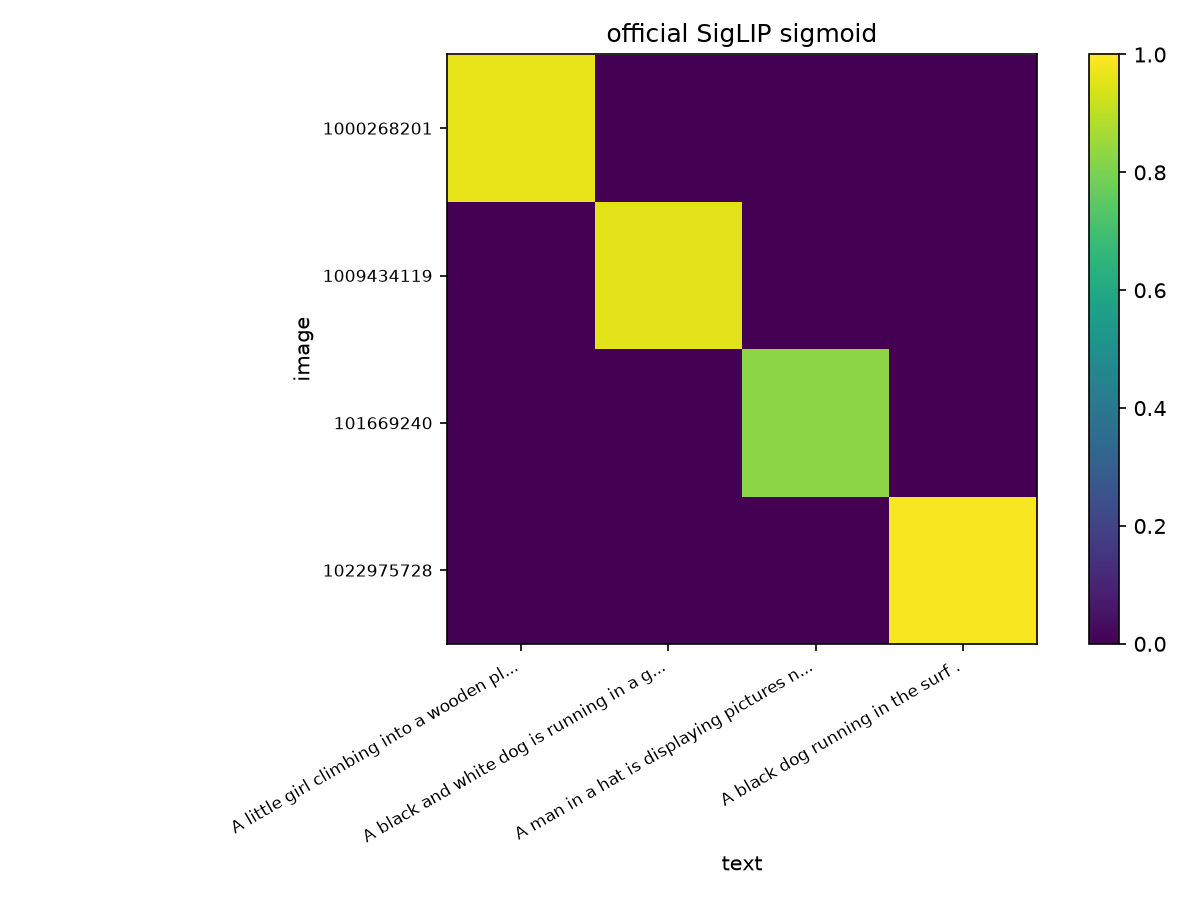

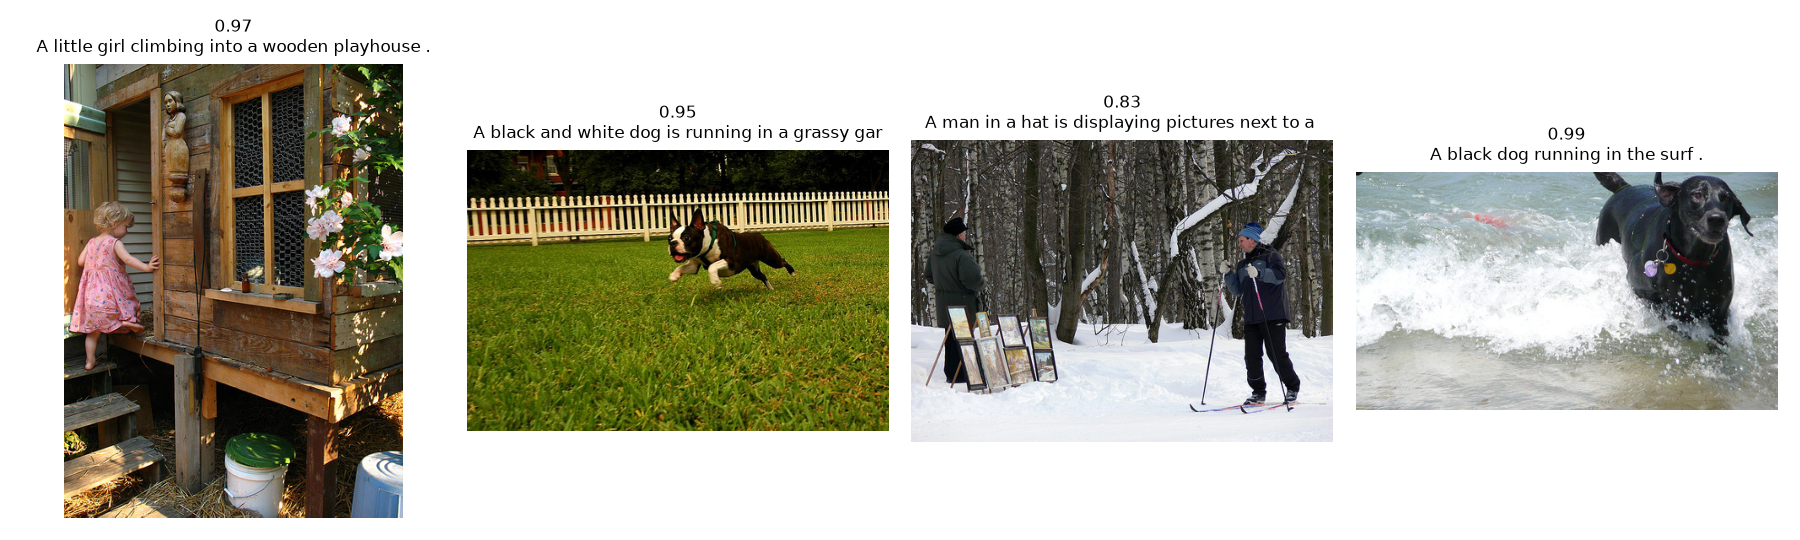

In [1]:
import torch
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

try:
    from transformers import AutoModel, AutoProcessor
except ImportError as exc:
    raise ImportError("先安装 transformers：pip install transformers") from exc

MODEL_ID = "google/siglip-base-patch16-224"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
print("model:", MODEL_ID)

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModel.from_pretrained(MODEL_ID).to(device).eval()

vis = model.config.vision_config
txt = model.config.text_config
print(
    f"vision: image={vis.image_size} patch={vis.patch_size} "
    f"hidden={vis.hidden_size} layers={vis.num_hidden_layers} heads={vis.num_attention_heads}"
)
print(
    f"text:   vocab={txt.vocab_size} max_len={txt.max_position_embeddings} "
    f"hidden={txt.hidden_size} layers={txt.num_hidden_layers} heads={txt.num_attention_heads}"
)


def n_params(module):
    return sum(p.numel() for p in module.parameters())


print(
    f"params: vision={n_params(model.vision_model)/1e6:.2f}M  "
    f"text={n_params(model.text_model)/1e6:.2f}M  "
    f"total={n_params(model)/1e6:.2f}M"
)
scale = model.logit_scale.detach().float().reshape(-1)[0].exp().item()
bias = model.logit_bias.detach().float().reshape(-1)[0].item()
print(f"logit_scale.exp()={scale:.4f}  logit_bias={bias:.4f}")

print("=" * 60)
print(model)
print("=" * 60)

root = Path("flickr8k-2k")
if not root.exists():
    root = Path("/home/ygz/cursor_workspace/Paper/SigLIP/flickr8k-2k")
names = [
    "1000268201_693b08cb0e.jpg",
    "1009434119_febe49276a.jpg",
    "101669240_b2d3e7f17b.jpg",
    "1022975728_75515238d8.jpg",
]
# 同一张图有 5 句 caption。第一张的 #0 写的是 entry way，图上是木制 playhouse，余弦只有 0.055。
# 换成写出 playhouse 的 #2。
cap_idx = {
    "1000268201_693b08cb0e.jpg": "2",
    "1009434119_febe49276a.jpg": "0",
    "101669240_b2d3e7f17b.jpg": "0",
    "1022975728_75515238d8.jpg": "0",
}
caps = {}
with open(root / "Flickr8k.token.txt", encoding="utf-8") as f:
    for line in f:
        key, text = line.rstrip("\n").split("\t", 1)
        img, idx = key.split("#")
        if img in cap_idx and idx == cap_idx[img]:
            caps[img] = text.strip()
missing = [n for n in names if n not in caps or not (root / "Flicker8k_Dataset" / n).exists()]
if missing:
    raise FileNotFoundError(f"{root} 缺少 {missing}")

texts = [caps[n] for n in names]
images = [Image.open(root / "Flicker8k_Dataset" / n).convert("RGB") for n in names]

# 官方训练用固定长度，必须 padding="max_length"，末位才是 EOS
inputs = processor(text=texts, images=images, padding="max_length", return_tensors="pt").to(device)
with torch.no_grad():
    outputs = model(**inputs)

logits = outputs.logits_per_image.float().cpu()
probs = torch.sigmoid(logits)
print("image_embeds", tuple(outputs.image_embeds.shape))
print("text_embeds", tuple(outputs.text_embeds.shape))
print("logits_per_image", tuple(logits.shape))
print("sigmoid 概率按图文对独立计算，一行不必加和为 1")

hit = 0
for i, name in enumerate(names):
    j = int(probs[i].argmax())
    hit += int(i == j)
    flag = "hit" if i == j else "miss"
    print(f"{flag}  {name}")
    for k, text in enumerate(texts):
        mark = "  <--" if k == j else ""
        print(f"    {probs[i, k]:.3f}  {text}{mark}")
print(f"match {hit}/{len(names)}")

out_dir = Path("/home/ygz/cursor_workspace/Paper/SigLIP")
short = [t if len(t) <= 42 else t[:39] + "..." for t in texts]
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(probs.numpy(), cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(texts)))
ax.set_yticks(range(len(names)))
ax.set_xticklabels(short, rotation=30, ha="right", fontsize=8)
ax.set_yticklabels([n.split("_")[0] for n in names], fontsize=8)
ax.set_xlabel("text")
ax.set_ylabel("image")
ax.set_title("official SigLIP sigmoid")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(out_dir / "sim_official.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, len(images), figsize=(12, 3.6))
for ax, image, row in zip(axes, images, probs):
    j = int(row.argmax())
    ax.imshow(image)
    ax.set_axis_off()
    ax.set_title(f"{row[j]:.2f}\n{texts[j][:48]}", fontsize=8)
fig.tight_layout()
fig.savefig(out_dir / "infer_official.png", dpi=150)
plt.show()
print("plots saved: sim_official.png, infer_official.png")


完整输出为：
```python
device: cuda
model: google/siglip-base-patch16-224
Loading weights: 100%|##########| 408/408 [00:00<00:00, 3575.52it/s]
vision: image=224 patch=16 hidden=768 layers=12 heads=12
text:   vocab=32000 max_len=64 hidden=768 layers=12 heads=12
params: vision=92.88M  text=110.27M  total=203.16M
logit_scale.exp()=117.3308  logit_bias=-12.9324
============================================================
SiglipModel(
  (text_model): SiglipTextModel(
    (embeddings): SiglipTextEmbeddings(
      (token_embedding): Embedding(32000, 768)
      (position_embedding): Embedding(64, 768)
    )
    (encoder): SiglipEncoder(
      (layers): ModuleList(
        (0-11): 12 x SiglipEncoderLayer(
          (self_attn): SiglipAttention(
            (q_proj/k_proj/v_proj/out_proj): Linear(768, 768)
          )
          (mlp): SiglipMLP(
            (activation_fn): GELUTanh()
            (fc1): Linear(768, 3072)
            (fc2): Linear(3072, 768)
          )
        )
      )
    )
    (final_layer_norm): LayerNorm(768)
    (head): Linear(768, 768)
  )
  (vision_model): SiglipVisionModel(
    (embeddings): SiglipVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=16, stride=16)
      (position_embedding): Embedding(196, 768)
    )
    (encoder): 同样 12 层 SiglipEncoderLayer
    (post_layernorm): LayerNorm(768)
    (head): SiglipMultiheadAttentionPoolingHead
  )
)
============================================================
image_embeds (4, 768)
text_embeds (4, 768)
logits_per_image (4, 4)
sigmoid 概率按图文对独立计算，一行不必加和为 1
hit  1000268201_693b08cb0e.jpg
    0.968  A little girl climbing into a wooden playhouse .  <--
    0.000  A black and white dog is running in a grassy garden surrounded by a white fence .
    0.000  A man in a hat is displaying pictures next to a skier in a blue hat .
    0.000  A black dog running in the surf .
hit  1009434119_febe49276a.jpg
    0.954  A black and white dog is running in a grassy garden surrounded by a white fence .  <--
hit  101669240_b2d3e7f17b.jpg
    0.827  A man in a hat is displaying pictures next to a skier in a blue hat .  <--
hit  1022975728_75515238d8.jpg
    0.988  A black dog running in the surf .  <--
match 4/4
plots saved: sim_official.png, infer_official.png
```